# Prophetmodel Leuven
Voorspellen van het effect van verschillende variabelen (academische kalender, evenementen en weer) op de drukte (aantal bezoekers per dag) in Leuven

- 1. **Basis druktemodel:** zonder parameters
- 2. **Basis druktemodel:** met vakantiedagen (academische kalender)
- 3. **Basis druktemodel:** met evenementen ipv academische kalender
- 4. **Model met weer:** evenementen + weerparameters (regen, temperatuur, wind, sneeuw)

Elk model wordt geëvalueerd op de **trainingsdata** (goodness of fit) en op een **testset** (de laatste 8 weken van de data, die het model niet gezien heeft).

## Inladen van de modules
* `pandas` en `numpy` voor data analyze
* `prophet` voor time series forecasting
* `matplotlib` voor visualisatie
* `os` voor directory

In [1]:
import pandas as pd
import numpy as np
import os
from prophet import Prophet
import matplotlib.pyplot as plt
from IPython.display import display, HTML
display(HTML("<style>:root { --jp-notebook-max-width: 100% !important; }</style>"))

Importing plotly failed. Interactive plots will not work.


# 1. **Basis Druktemodel:** Zonder parameters 


## 1.1. Inladen data

In [2]:
# De datasets staan in dezelfde map als deze notebook, dus we hoeven niet van map te wisselen.
# (Het pad hieronder was het pad van de docent en bestaat niet op deze computer.)
# os.chdir('c:/users/u0169599/OneDrive - Thomas More/Data Science Course/3e bach - Machine Learning/datasets')

In [3]:
# Controleren in welke map we werken
print("Huidige werkmap:", os.getcwd())
print("\nBestanden in deze map:")
for file in os.listdir():
    if file.endswith('.xlsx') or file.endswith('.csv'):
        print(f" - {file}")

Huidige werkmap: c:\Users\chayb\Desktop\2026-2027 Semester 1\Machine learning & Forecasting\Les 7

Bestanden in deze map:
 - Academische_kalender_2022_2025.xlsx
 - Evenementen_Leuven.xlsx
 - Leuven bestedingen 2023 - 2024.xlsx
 - Leuven bezoekers 2023 - 2024.xlsx
 - Leuven weerdata 2023 - 2024.csv


1. **Data inladen**: met `pd.read_excel` laden we de Excel-bestanden in. De bestanden staan in dezelfde map als de notebook.
2. **Data in het juiste formaat zetten**: Prophet verwacht een dataframe met exact twee kolommen: **ds** (datum) en **y** (de waarde die we willen voorspellen). Andere kolomnamen geven een foutmelding.

### 1.1.1: **Bezoekersdata**

Bezoekersdata (`daily_total_visits`) inladen en in juiste format voor prophetmodel plaatsen (**ds**: datum en **y**: aantal bezoekers)

In [4]:
# Bezoekersdata inladen
passanten = pd.read_excel("Leuven bezoekers 2023 - 2024.xlsx")

# Datum correct zetten
passanten['Datum'] = pd.to_datetime(passanten['Datum'], format = '%Y-%m-%d')

# Verwijderen van . en cijfer in de kolom 'Herkomstprofiel' en witruimte verwijderen
passanten['Herkomstprofiel'] = passanten['Herkomstprofiel'].str.replace(r'^\d+\.\s*', '', regex=True).str.strip()

# Groeperen van de data by Datum en bereken het aantal bezoekers voor elke dag
daily_total_visits = passanten[['Datum', 'Aantal bezoeken']].groupby(['Datum']).sum().reset_index()

# herbenoemen van de kolommen voor Prophet model (ds = date en y = voor target variable)
daily_total_visits = daily_total_visits.rename(columns = {'Datum': 'ds', 'Aantal bezoeken': 'y'})

# Data sorteren op datum (ds)
daily_total_visits.sort_values(by='ds', inplace =  True)

# Dataframe
daily_total_visits.head(3)

,ds,y
0,2023-01-01,54534
1,2023-01-02,61980
2,2023-01-03,77460


#### Visualiseer het aantal bezoekers

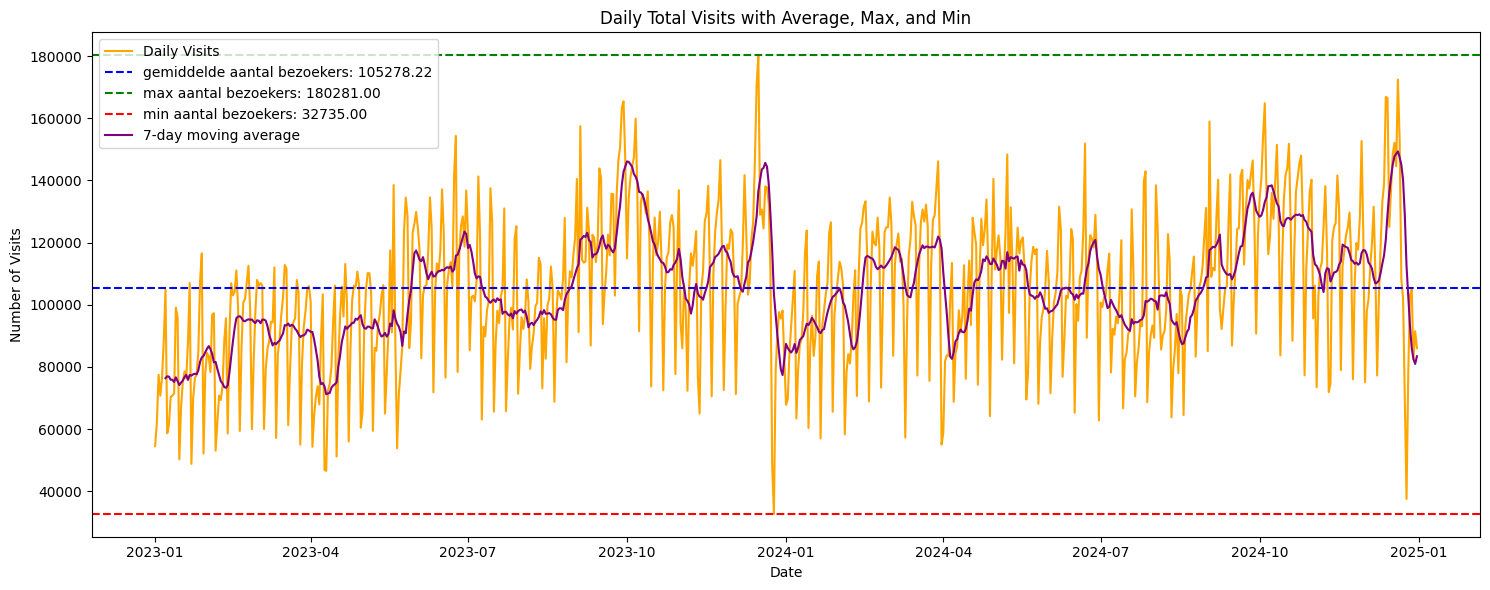

In [5]:
# Plot het aantal bezoekers

# Grootte van de figuur instellen
plt.figure(figsize=(15,6))
# Plot het aantal bezoekers
plt.plot(daily_total_visits['ds'], daily_total_visits['y'], label = 'Daily Visits', color = 'orange')

# Gemiddelde, max en min bezoekers berekenen
avg_visits = daily_total_visits['y'].mean()
max_visits = daily_total_visits['y'].max()
min_visits = daily_total_visits['y'].min()

# Voeg de gemiddelde, max en min bezoekers toe aan de plot
plt.axhline(avg_visits, color = 'blue', linestyle = '--', label = f'gemiddelde aantal bezoekers: {avg_visits:.2f}')
plt.axhline(max_visits, color = 'green', linestyle = '--', label = f'max aantal bezoekers: {max_visits:.2f}')
plt.axhline(min_visits, color = 'red', linestyle = '--', label = f'min aantal bezoekers: {min_visits:.2f}')

# bereken en plot het 7-daags moving gemiddelde om de trend te visualiseren
daily_total_visits['7_day_avg'] = daily_total_visits['y'].rolling(window=7).mean()  
plt.plot(daily_total_visits['ds'], daily_total_visits['7_day_avg'], label = '7-day moving average', color = 'purple', linestyle = '-')

# titel en labels
plt.title('Daily Total Visits with Average, Max, and Min')
plt.xlabel('Date')
plt.ylabel('Number of Visits')

# voeg een legende toe
plt.legend()

# Toon de plot
plt.tight_layout()
plt.show()

#### **Conclusie**

Trend loopt enigszins gelijk met de het academiejaar. Tijdens de vakantieszijn er minder bezoekers in Leuven. Telkens een aanzienlijke dalingen in de maanden januari (examens?).


## 1.2. Prophet Forecast

* m = `Prophet()`: construeer het prophet model (parameters: yearly_seansonality, seasonality_mode, etc.)
* m.`fit()`: fit het model op de historische data (format: ds, y)
* `forecast_days = `: het aantal dagen dat het model dient te voorspellen
* future = m.`make_future_dataframe(periods = forecast_days)`: het dataframe met de historische en toekomstige data
* forecast = m.`predict(future)`: maak de voorspelling
* forecast.loc[forecast['yhat'] < 0, yhat] = 0: negatieve voorspellingen naar 0 omzetten
* m.`plot_components(forecast)`: plot de voorspelling 

c:\Users\chayb\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
11:53:05 - cmdstanpy - INFO - Chain [1] start processing
11:53:05 - cmdstanpy - INFO - Chain [1] done processing


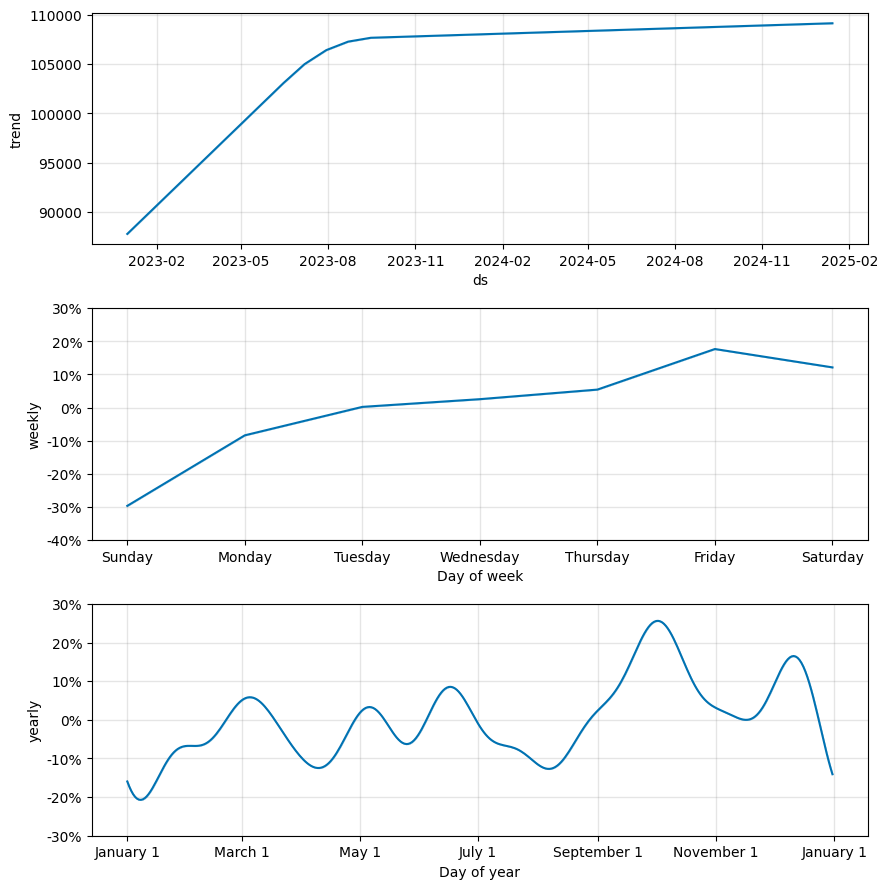

In [6]:
# Maak een Prophet model met jaarlijkse seizoensgebondenheid
m = Prophet(yearly_seasonality=True, seasonality_mode='multiplicative')

# fit het model op de historische data
m.fit(daily_total_visits)

# bepaal hoeveel dagen in de toekomst we willen voorspellen
forecast_days = 14

# maak een dataframe dat zowel de historische data als de toekomstige data bevat
future = m.make_future_dataframe(periods=forecast_days)

# bekijk de structuur van het dataframe
future

# maak de voorspelling
forecast = m.predict(future)

# toon enkel de kolommen die we willen zien van de voorspelling
# - 'ds' = date
# - 'yhat' = predicted value
# - 'yhat_lower' and 'yhat_upper' = uncertainty interval
forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail()

# Zet elke negatieve waarde in de voorspelling naar 0
forecast.loc[forecast['yhat'] < 0, 'yhat'] = 0

# plot de voorspellingen
fig2 = m.plot_components(forecast)


##### **Conclusie**: Basis Druktemodel aantal bezoekers

Toenemende `trend` naar het einde van de meting, maar lijkt eerder af te vlakken vanaf 8/2023. De `weekly trend` geeft een stijging van het aantal bezoekers weer naar vrijdag toe, om dan weer sterk te dalen. De `yearly` trend geeft jaarlijkse pieken die zich situeren eind september-oktober, begin december.

## 1.3: Prophet Forecast: Error

Text(0.5, 1.0, 'afwijking van de voorspelling')

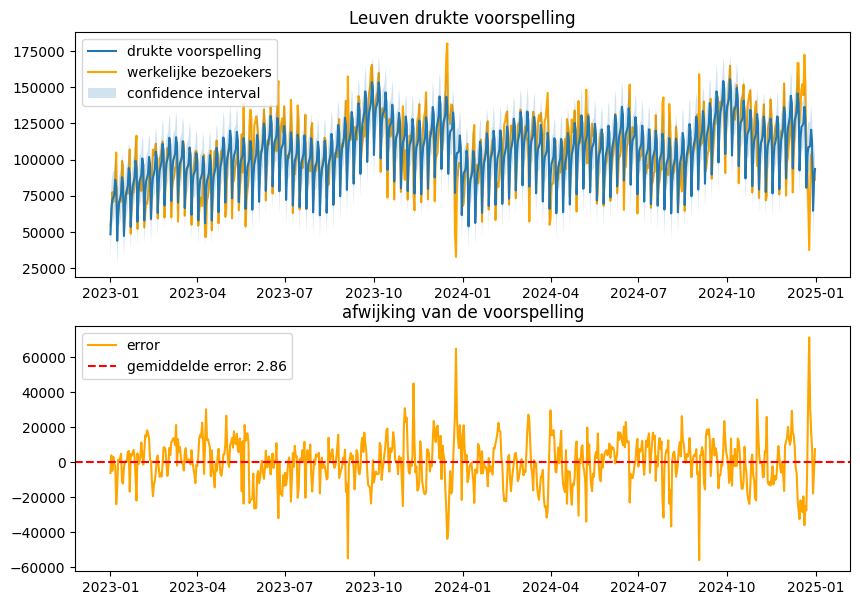

In [7]:
# Filter de voorspelling om enkel toekomstige data te tonen
forecast_new = forecast[forecast['ds'] > daily_total_visits['ds'].max()]

# Merge de voorspelling met de originele data ('ds')
ProphetFit = forecast.merge(daily_total_visits, on = 'ds')

# Bereken de afwijking van de voorspelling ('yhat') tov de actuele bezoekers ('y')
# positieve afwijking = overschatting, nagatieve afwijking = onderschatting
ProphetFit['error'] = ProphetFit['yhat'] - ProphetFit['y']

# Figuurgrootte instellen
plt.figure(figsize=(10, 7))



# --- Plot 1: Plot de voorspelling met de werkelijke bezoekersaantallen ---
plt.subplot(2, 1, 1)
# plot de voorspelling van Prophet
plt.plot(ProphetFit['ds'], ProphetFit['yhat'], label = 'drukte voorspelling', zorder = 1)

# plot de werkelijke bezoekersaantallen
plt.plot(ProphetFit['ds'], ProphetFit['y'], label = 'werkelijke bezoekers', zorder = 0, color = 'orange')

# confidence intervan rond de voorspelling
plt.fill_between(
    ProphetFit['ds'],
    ProphetFit['yhat_upper'],
    ProphetFit['yhat_lower'],
    alpha = 0.2,
    label = 'confidence interval')

# Titel en labels toevoegen
plt.legend()
plt.title('Leuven drukte voorspelling')

# --- Plot 2: Plot de afwijking van de voorspelling over tijd ---
plt.subplot(2, 1, 2)
plt.plot(ProphetFit['ds'], ProphetFit['error'], label = 'error', color = 'orange', zorder = 0)
avg_error = ProphetFit['error'].mean()
plt.axhline(avg_error, color = 'red', linestyle = '--', label = f'gemiddelde error: {avg_error:.2f}')
plt.legend()
plt.title('afwijking van de voorspelling')


#### **Conclusie**: Error Basis Prophet Druktemodel aantal bezoekers
De gemiddelde error is bijna 0 (± 3 bezoekers). Dat betekent dat het model **niet systematisch** over- of onderschat, maar het zegt niets over hoe groot de fouten zijn: positieve en negatieve fouten heffen elkaar op. Daarvoor kijken we naar de RMSE (± 13.200 bezoekers, zie 3.4) en de MAPE (± 10 %).

Op de errorplot zie je dat de meeste dagen binnen ± 20.000 bezoekers voorspeld worden, maar er zijn grote uitschieters: bv. **kerstdag 2024** (± 71.000 overschat) en begin september 2024 (± 56.000 onderschat). Op zulke speciale dagen weet het basismodel niet dat er iets bijzonders is. Daarom voegen we in de volgende modellen de academische kalender en de evenementen toe.

# 2. **Basis Druktemodel:** Met vakantiedagen (Academische kalender)

## 2.1: Inladen data vakantiedagen en academische kalender

Er zal in de eerste analyse gekozen worden voor de academische kalender aangezien deze de bezoekersaantal op het eerste zicht lijkt te beïnvloeden

In [8]:
os.listdir()
# print(os.getcwd())

['Academische_kalender_2022_2025.xlsx',
 'Deel 2 - Oefening.ipynb',
 'Evenementen_Leuven.xlsx',
 'Leuven bestedingen 2023 - 2024.xlsx',
 'Leuven bezoekers 2023 - 2024.xlsx',
 'Leuven weerdata 2023 - 2024.csv']

In [9]:
# academische_kalender inladen
evenementen_leuven = pd.read_excel("Academische_kalender_2022_2025.xlsx")


In [10]:
# datum correct zetten
evenementen_leuven['Datum'] = pd.to_datetime(evenementen_leuven['Datum'], format = '%Y-%m-%d')

# academische_kalender['Datum'] = pd.to_datetime(academische_kalender['Datum'], format = '%y-%m-%d')

# merge in geval van beide dataframes samen (academische kalender en evenementen)
# evenementen_leuven = pd.concat([evenementen_leuven, academische_kalender], ignore_index = True)

# lower case activiteit
evenementen_leuven['activiteit'] = evenementen_leuven['activiteit'].str.lower()

# verwijder nan
evenementen_leuven = evenementen_leuven[evenementen_leuven['activiteit'].notna()]

# Dataframe
evenementen_leuven['activiteit'].value_counts()

activiteit
examenperiode            179
blokperiode              115
lesvrije week             26
orientatiedagen           14
startersdagen              6
start lessen               4
opening academiejaar       3
start tweede semester      1
Name: count, dtype: int64

## 2.2: Prophet model met academische kalender

* `holidays =`: maak een dataframe met de activiteiten (**ds**: datum, **holiday**: activiteit)
* m2 = `Prophet(holidays = holidays, ...)`: construeer het prophet model **met vakantiedagen (holidays)** en volgende parameters (yearly_seasonality, seasonality_mode, mcmc_samples etc.)
* m2`.fit()`: fit het model op de data
* forecast_days, make_future_dataframe(periods = forecast_days), m2predict(),..

In [11]:
## Prophet model met evenementen

# herbenoemen van de activiteiten kolom volgens het prophet model
holidays = evenementen_leuven.rename(columns = {'Datum': 'ds', 'activiteit': 'holiday'})
# prophet model met vakantiedagen
m2 = Prophet(holidays = holidays, yearly_seasonality = True, seasonality_mode = 'additive', mcmc_samples = 500)
# fit het model op de historische data
m2.fit(daily_total_visits)
# definieer de toekomst
forecast_days = 14
# maak een dataframe dat de historische en de toekomstige data bevat
future2 = m2.make_future_dataframe(periods = forecast_days)
# maak de voorspelling
forecast2 = m2.predict(future2)
# zet alle negatieve waarden in de voorspelling naar 0
forecast2.loc[forecast2['yhat'] < 0, 'yhat'] = 0
# geef de voorspelling weer
forecast2[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail()

11:53:07 - cmdstanpy - INFO - CmdStan start processing
chain 1:   0%|          | 0/500 [00:00<?, ?it/s, (Warmup)]




chain 1:  20%|██        | 100/500 [00:02<00:08, 46.36it/s, (Warmup)]

chain 1:  40%|████      | 200/500 [00:05<00:09, 32.34it/s, (Warmup)]



chain 1:  50%|█████     | 251/500 [00:07<00:07, 31.99it/s, (Sampling)]




chain 1:  70%|███████   | 350/500 [00:10<00:04, 33.71it/s, (Sampling)]


chain 1:  90%|█████████ | 450/500 [00:12<00:01, 35.52it/s, (Sampling)]


chain 1: 100%|██████████| 500/500 [00:13<00:00, 37.22it/s, (Sampling)]

chain 2: 100%|██████████| 500/500 [00:14<00:00, 35.08it/s, (Sampling completed)]

chain 3: 100%|██████████| 500/500 [00:14<00:00, 35.08it/s, (Sampling completed)]


chain 4: 100%|██████████| 500/500 [00:14<00:00, 35.08it/s, (Sampling completed)]


11:53:21 - cmdstanpy - INFO - CmdStan done processing.
11:53:21 - cmdstanpy - WARNING - Non-fatal error during sampling:
Exception: normal_id_glm_lpdf: Matrix of independent variables is inf, but must be finite! (in 'prophet.stan', line 137, column 2 to line 142, column 4)
	Exception: normal_id_glm_lpdf: Matrix of independent variables is inf, but must be finite! (in 'prophet.stan', line 137, column 2 to line 142, column 4)
	Exception: normal_id_glm_lpdf: Scale vector is 0, but must be positive finite! (in 'prophet.stan', line 137, column 2 to line 142, column 4)
	Exception: normal_id_glm_lpdf: Matrix of independent variables is inf, but must be finite! (in 'prophet.stan', line 137, column 2 to line 142, column 4)
Exception: normal_id_glm_lpdf: Matrix of independent variables is inf, but must be finite! (in 'prophet.stan', line 137, column 2 to line 142, column 4)
	Exception: normal_id_glm_lpdf: Matrix of independent variables is inf, but must be finite! (in 'prophet.stan', line 137, 

,ds,yhat,yhat_lower,yhat_upper
740,2025-01-10,105045.619882,86871.426525,123580.513260
741,2025-01-11,99451.423658,81372.757532,117436.360151
742,2025-01-12,55340.410231,37902.657939,73545.587868
743,2025-01-13,86915.259433,68720.276897,104583.042507
744,2025-01-14,96464.480348,77840.751630,114819.646574


* m2`.plot_components()`: plot de componenten van de voorspelling (in dit geval de academische kalenders)

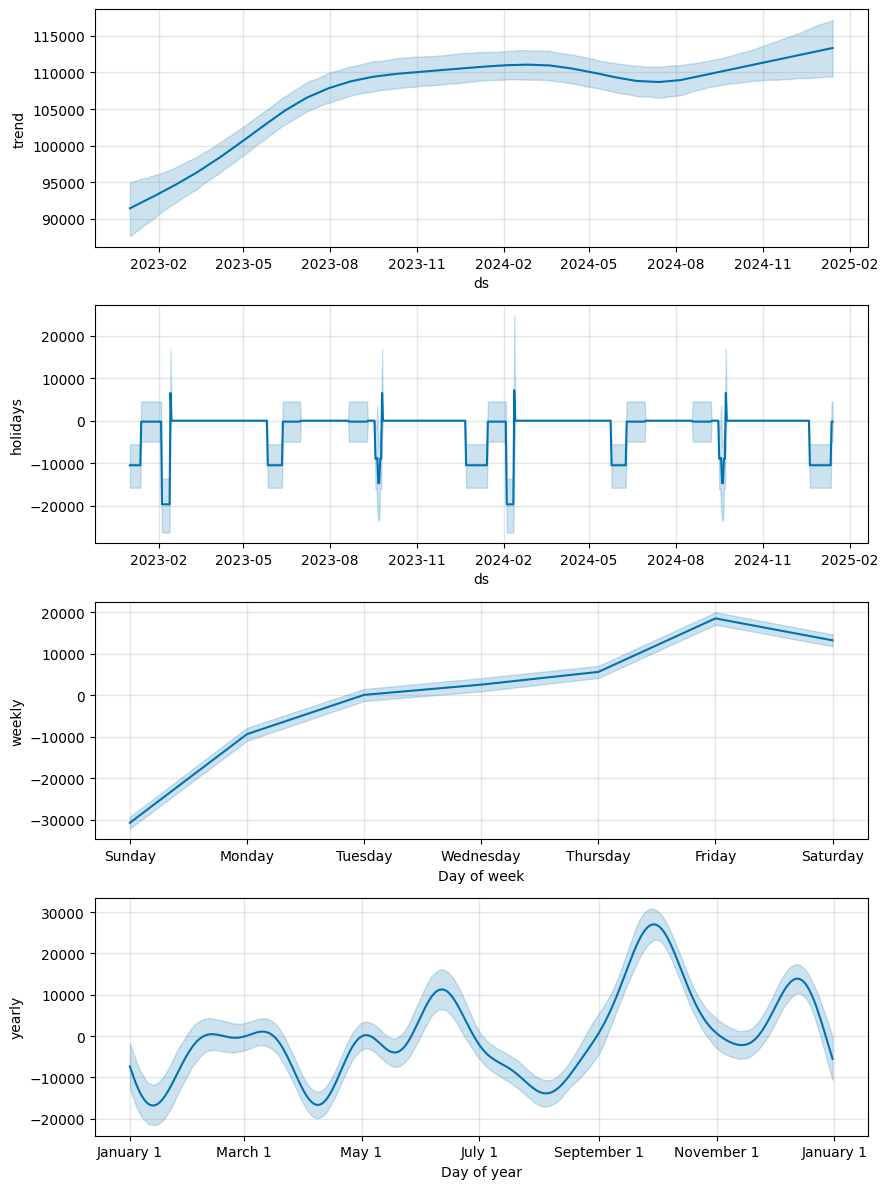

In [12]:
fig2 = m2.plot_components(forecast2)

## 2.3: Visualisatie Prophet model met academische kalender

Text(0, 0.5, 'Negatief effect')

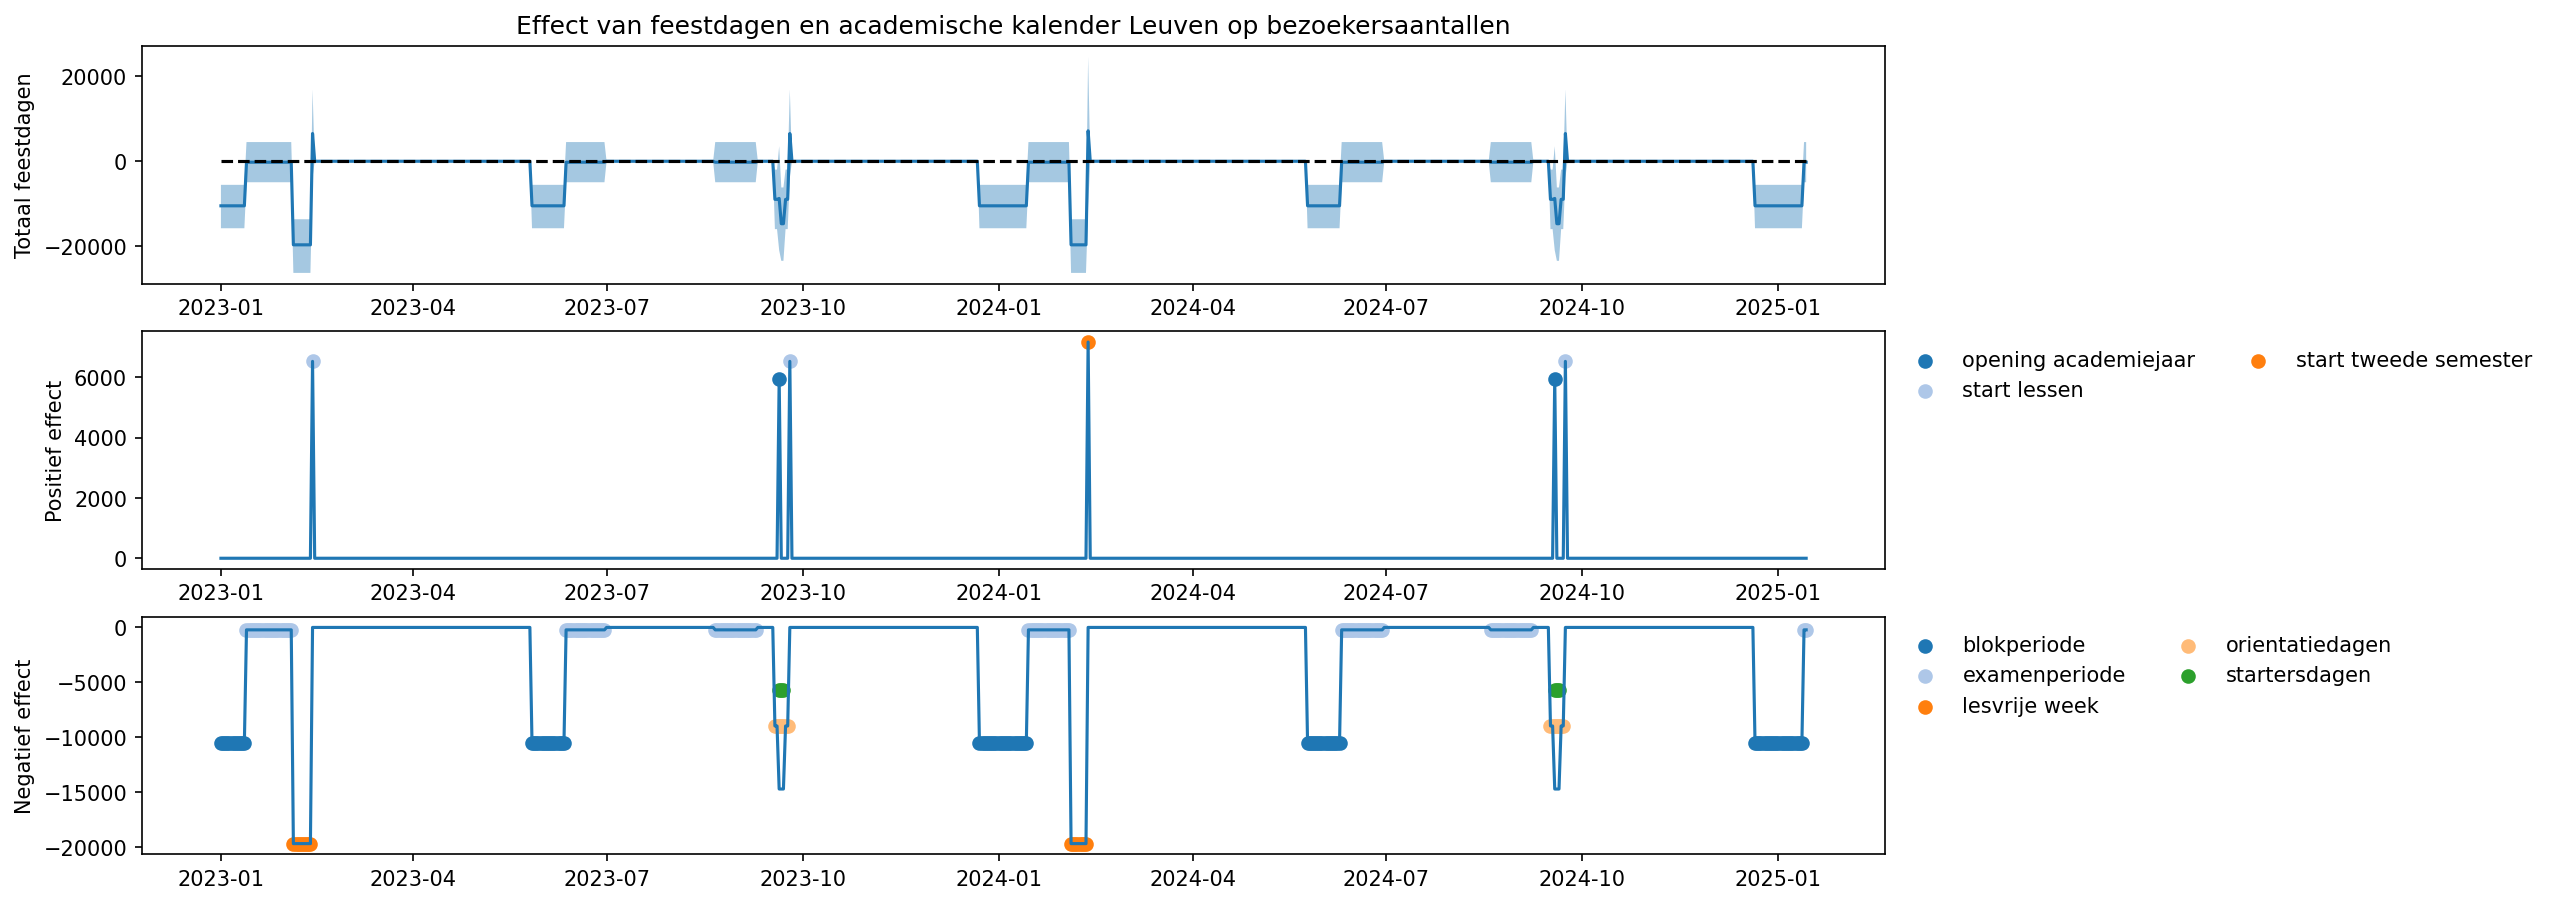

In [13]:
# Kleuren importeren uit plt
colormap = plt.cm.tab20
# Figuurgrootte instellen
plt.figure(figsize = (15, 7), dpi = 150)

# --- plot 1: effect van vakantiedagen (academische kalender) op Leuven ---
plt.subplot(3, 1, 1)  # drie plots onder elkaar, werken op de eerste plot 
# vakantiedagen over de tijd
plt.plot(forecast2['ds'], forecast2['holidays'])
# voeg de onzekerheid intervallen voor de vakantiedagen toe
plt.fill_between(forecast2['ds'], forecast2['holidays_lower'], forecast2['holidays_upper'], alpha = 0.4)
# horizontale lijn op 0 voor baseline
plt.hlines(0, xmin = forecast2['ds'].min(), xmax = forecast2['ds'].max(), color = 'black', linestyle = 'dashed')
# titel en llabels
plt.title('Effect van feestdagen en academische kalender Leuven op bezoekersaantallen')
plt.ylabel('Totaal feestdagen')

# --- Positieve effecten van vakantiedagen in Leuven ---
plt.subplot(3, 1, 2)  # werken op de tweede plot

# Initialize counters and lists for storing positive holiday effects data
tellingpos = 0
postext = []

# Loop through each holiday event and calculate the positive effect (if any)
for feestdag in evenementen_leuven['activiteit'].unique():
    # Check if the positive effect for the current holiday is greater than a small threshold
    if forecast2.iloc[:, forecast2.columns == feestdag].values.max() > 0.01:
        # First holiday event with positive effect
        if tellingpos == 0:
            pos_ef = forecast2.iloc[:, forecast2.columns == feestdag].copy()
            pos_ef.columns = ['Pos']
            pos_ef['ds'] = forecast2['ds']
            
            pos_ef_text = pos_ef[pos_ef['Pos'] == pos_ef['Pos'].max()].copy()
            pos_ef_text['holiday'] = feestdag
            postext.append(pos_ef_text)
        else:
            # Subsequent holiday events with positive effects
            pos_ef2 = forecast2.iloc[:, forecast2.columns == feestdag].copy()
            pos_ef2.columns = ['Pos']
            pos_ef2['ds'] = forecast2['ds']
            pos_ef['Pos'] = pos_ef['Pos'] + pos_ef2['Pos']
            
            pos_ef_text = pos_ef2[pos_ef2['Pos'] == pos_ef2['Pos'].max()].copy()
            pos_ef_text['holiday'] = feestdag
            postext.append(pos_ef_text)
        tellingpos += 1  # Increment counter for the number of positive events
    
# Combine the positive effects data
postext = pd.concat(postext, ignore_index=True)

# Plot the cumulative positive effects over time
plt.plot(pos_ef['ds'], pos_ef['Pos'])

# Color the positive effects for different holidays
colcter = 0
for poshol in postext['holiday'].unique():
    plt.scatter(postext.loc[postext['holiday'] == poshol, 'ds'], postext.loc[postext['holiday'] == poshol, 'Pos'], 
                label=poshol, color=colormap(colcter))
    colcter += 1  # Increment counter for different colors in the colormap

# Add legend and labels to the second plot (moving the legend outside the graph)
plt.legend(ncol=2, frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
plt.ylabel('Positief effect')

# --- plot 3: Negatieve effect van vakantiedagen op Leuven ---
plt.subplot(3, 1, 3)
# start tellers en lijst voor de positieve effecten van vakantiedagen
tellingneg = 0
negtext = []

# Loop door de feestdagen en bereken de negatieve effecten
for feestdag in evenementen_leuven['activiteit'].unique():
    # Check if the negative effect for the current holiday is less than a small negative threshold
    if forecast2.iloc[:, forecast2.columns == feestdag].values.min() < -0.01:
        # First holiday event with negative effect
        if tellingneg == 0:
            neg_ef = forecast2.iloc[:, forecast2.columns == feestdag].copy()
            neg_ef.columns = ['Neg']
            neg_ef['ds'] = forecast2['ds']
            
            neg_ef_text = neg_ef[neg_ef['Neg'] == neg_ef['Neg'].min()].copy()
            neg_ef_text['holiday'] = feestdag
            negtext.append(neg_ef_text)
        else:
            # Subsequent holiday events with negative effects
            neg_ef2 = forecast2.iloc[:, forecast2.columns == feestdag].copy()
            neg_ef2.columns = ['Neg']
            neg_ef2['ds'] = forecast2['ds']
            neg_ef['Neg'] = neg_ef['Neg'] + neg_ef2['Neg']
            
            neg_ef_text = neg_ef2[neg_ef2['Neg'] == neg_ef2['Neg'].min()].copy()
            neg_ef_text['holiday'] = feestdag
            negtext.append(neg_ef_text)
            
        tellingneg += 1  # Increment counter for the number of negative events
        
# Combine the negative effects data
negtext = pd.concat(negtext, ignore_index=True)

# Plot the cumulative negative effects over time
plt.plot(neg_ef['ds'], neg_ef['Neg'])

# Color the negative effects for different holiday
colcter = 0
for neghol in negtext['holiday'].unique():
    plt.scatter(negtext.loc[negtext['holiday'] == neghol, 'ds'], negtext.loc[negtext['holiday'] == neghol, 'Neg'], 
                label=neghol, color=colormap(colcter))
    colcter += 1  # Increment counter for different colors in the colormap    

# Add legend and labels to the third plot (moving the legend outside the graph)
plt.legend(ncol=2, frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
plt.ylabel('Negatief effect')

In [14]:
# Filter the forecast2 DataFrame to only include rows where 'ds' (dates) are after the maximum date in 'daily_total_visits'
forecast_new2 = forecast2[forecast2['ds'] > daily_total_visits['ds'].max()]

# Merge the 'forecast2' DataFrame with 'daily_total_visits' on the 'ds' (date) column to align the forecast with the actual data
ProphetFit2 = forecast2.merge(daily_total_visits, on='ds')

# Calculate the error as the difference between the predicted values ('yhat') and the actual values ('y')
ProphetFit2['error'] = ProphetFit2['yhat'] - ProphetFit2['y']



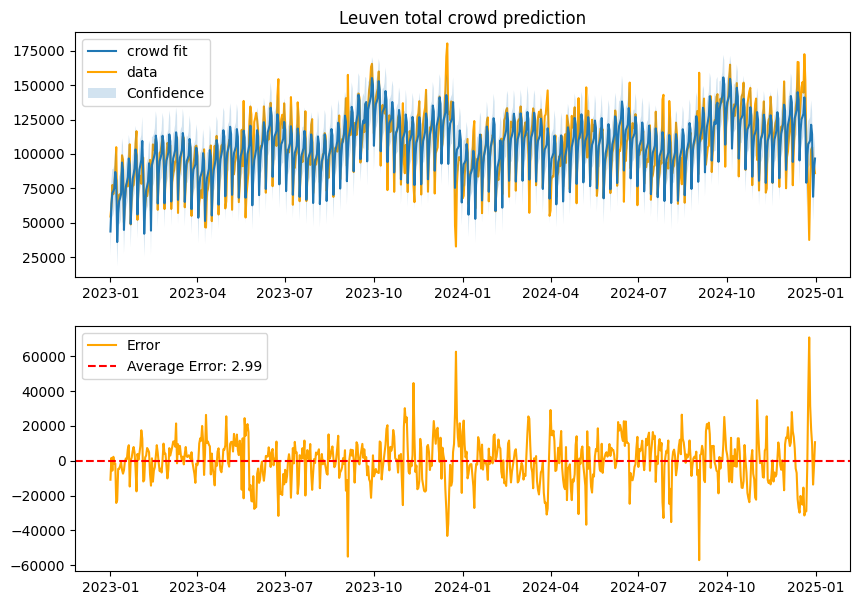

In [15]:
# Create a figure with specified dimensions (10x7 inches)
plt.figure(figsize=(10,7))

# --- Plot 1: Drukte Fit vs. Actual Data ---
# Create the first subplot (2 rows, 1 column, first subplot)
plt.subplot(2,1,1)

# Plot the fitted values (crowd fit) from the Prophet model, setting its zorder to 1 for proper layering
plt.plot(ProphetFit2['ds'], ProphetFit2['yhat'], label='crowd fit', zorder = 1)

# Plot the actual data (real observed values), in orange color, with zorder 0 to ensure it's behind the fit plot
plt.plot(ProphetFit2['ds'], ProphetFit2['y'], label='data', zorder = 0, color = 'orange') 

# Add a shaded area to represent the confidence interval between the upper and lower predicted values
plt.fill_between(ProphetFit2['ds'], ProphetFit2['yhat_upper'], ProphetFit2['yhat_lower'],
                 alpha=.2, label='Confidence')  # alpha=0.2 makes the fill semi-transparent

# Add a title to the first plot
plt.title('Leuven total crowd prediction')

# Add a legend to the plot to label the lines
plt.legend()

# --- Plot 2: Error Plot ---
# Create the second subplot (2 rows, 1 column, second subplot)
plt.subplot(2,1,2)

# Plot the error (difference between actual and predicted) as a line, using orange color
plt.plot(ProphetFit2['ds'], ProphetFit2['error'], label='Error', zorder = 0, color = 'orange')

# Calculate and draw average error line
avg_error = ProphetFit2['error'].mean()
plt.axhline(avg_error, color='red', linestyle='--', label=f'Average Error: {avg_error:.2f}')

# Add legend
plt.legend()

# Uncomment the next line to save the plot as a PNG file if needed
# plt.savefig('prophet_forecast.png')

# Display the plots
plt.show()

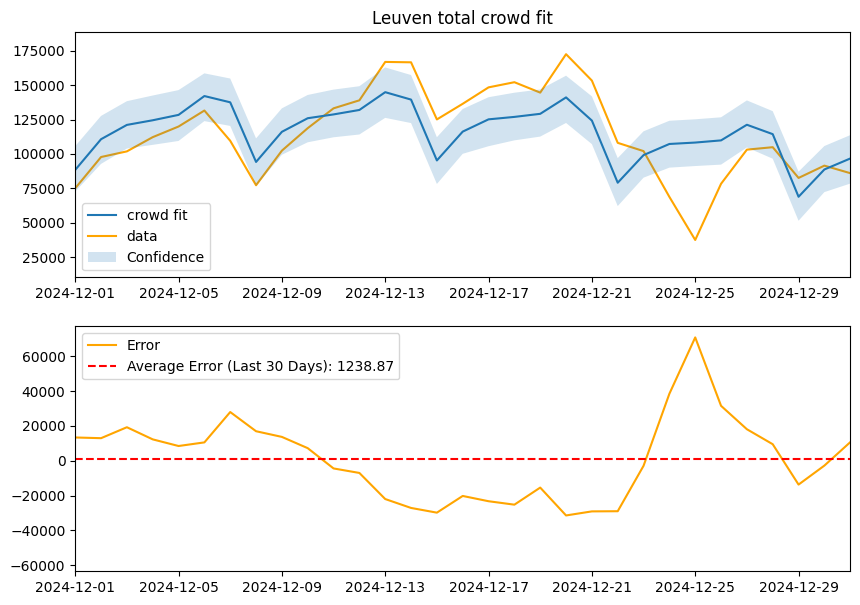

In [16]:
import datetime  # So we can do time calculations like "last 30 days"

plt.figure(figsize=(10, 7))  # Set up a figure that's 10x7 inches big

# --- TOP PLOT: Forecast vs Actual Data ---
plt.subplot(2, 1, 1)  # First subplot (1st of 2 stacked vertically)

# Plot the forecasted crowd (from Prophet)
plt.plot(ProphetFit2['ds'], ProphetFit2['yhat'], label='crowd fit', zorder=1)

# Plot the actual recorded data
plt.plot(ProphetFit2['ds'], ProphetFit2['y'], label='data', zorder=0, color='orange')

# Add the confidence interval (shaded area showing uncertainty)
plt.fill_between(ProphetFit2['ds'], ProphetFit2['yhat_upper'], ProphetFit2['yhat_lower'], alpha=.2, label='Confidence')

plt.title('Leuven total crowd fit')  # Title for the top plot
plt.legend()  # Add legend to explain the colors
plt.xlim([ProphetFit2['ds'].max() - datetime.timedelta(days=30), ProphetFit2['ds'].max()])  # Zoom in to last 30 days

# --- BOTTOM PLOT: Forecast Error ---
plt.subplot(2, 1, 2)  # Second subplot (2nd of 2)

# Plot how off the predictions were (forecast - actual)
plt.plot(ProphetFit2['ds'], ProphetFit2['error'], label='Error', zorder=0, color='orange')

plt.xlim([ProphetFit2['ds'].max() - datetime.timedelta(days=30), ProphetFit2['ds'].max()])  # Also zoom into last 30 days

# Calculate the average forecast error for the last 30 days
avg_error_last_30_days = ProphetFit2[ProphetFit2['ds'] >= ProphetFit2['ds'].max() - datetime.timedelta(days=30)]['error'].mean()
plt.axhline(avg_error_last_30_days, color='red', linestyle='--', label=f'Average Error (Last 30 Days): {avg_error_last_30_days:.2f}')
plt.legend()

# Add legend
plt.legend()

# plt.savefig('prophet_forecast.png')  # If you wanna save it, just uncomment this
plt.show()  # Actually display the plots


# 3. **Basis Druktemodel:** met feestdagen ipv academische kalender

>**Taak:** Druktemodel met feestdagen

## 3.1: Inladen evenementen

In [17]:
for file in os.listdir():
    print (f" - {file}")

 - Academische_kalender_2022_2025.xlsx
 - Deel 2 - Oefening.ipynb
 - Evenementen_Leuven.xlsx
 - Leuven bestedingen 2023 - 2024.xlsx
 - Leuven bezoekers 2023 - 2024.xlsx
 - Leuven weerdata 2023 - 2024.csv


In [18]:
# Evenementen inladen
evenementen_leuven = pd.read_excel("Evenementen_Leuven.xlsx")

# 1) Kolomnamen opkuisen: in de Excel staan er spaties achter de namen (bv. 'Titel ')
evenementen_leuven.columns = evenementen_leuven.columns.str.strip()

# 2) Enkel de relevante kolommen houden en rijen zonder datum of titel verwijderen
evenementen_leuven = evenementen_leuven[['Datum', 'Titel', 'Type']].dropna(subset=['Datum', 'Titel'])
evenementen_leuven['Datum'] = pd.to_datetime(evenementen_leuven['Datum'], format='%Y-%m-%d')

# 3) Titels uniformiseren: witruimte weg + lower case ('Solden' en 'solden' zijn hetzelfde evenement)
evenementen_leuven['Titel'] = evenementen_leuven['Titel'].str.strip().str.lower()
evenementen_leuven['Type'] = evenementen_leuven['Type'].str.strip().str.lower().fillna('andere')
evenementen_leuven.loc[evenementen_leuven['Type'].str.startswith('andere'), 'Type'] = 'andere'

# 4) Tikfouten en varianten van hetzelfde evenement samenvoegen
correcties = {
    'winteruin': 'wintertuin',
    'worl cup mtb eliminator': 'world cup mtb eliminator',
    'world cup mbt eliminator': 'world cup mtb eliminator',
    'gp jef scherens': 'grote prijs jef scherens',
    'jef scherens prijs': 'grote prijs jef scherens',
    'autoloze zondag': 'autovrije zondag',
    'countdown': 'leuven countdown',
    'triatlon': 'city triathlon',
    'brabantse pijl cyclo': 'brabantse pijl',
    'vlaams-brabantse pijl': 'brabantse pijl',
    'mode in leuven': 'sustainable day mode in leuven',
}
evenementen_leuven['Titel'] = evenementen_leuven['Titel'].replace(correcties)

# 5) Enkel de periode van de bezoekersdata (+ de 14 voorspelde dagen) houden
start = daily_total_visits['ds'].min()
einde = daily_total_visits['ds'].max() + pd.Timedelta(days=14)
evenementen_leuven = evenementen_leuven[(evenementen_leuven['Datum'] >= start) & (evenementen_leuven['Datum'] <= einde)]

# 6) Dubbele rijen (zelfde evenement op dezelfde dag) verwijderen
evenementen_leuven = evenementen_leuven.drop_duplicates(subset=['Datum', 'Titel'])

# 7) Zeldzame evenementen (< 3 dagen in de data) groeperen per type.
#    Prophet schat per evenement een apart effect; met 1 of 2 datapunten is dat effect
#    niet betrouwbaar te schatten (overfitting). Daarom: 'overig cultureel', 'overig sport', ...
aantal_dagen = evenementen_leuven['Titel'].value_counts()
zeldzaam = evenementen_leuven['Titel'].isin(aantal_dagen[aantal_dagen < 3].index)
evenementen_leuven.loc[zeldzaam, 'Titel'] = 'overig ' + evenementen_leuven.loc[zeldzaam, 'Type']

# Zelfde kolomnaam als bij de academische kalender
evenementen_leuven = evenementen_leuven.rename(columns={'Titel': 'activiteit'})

print(f"Aantal evenementdagen: {len(evenementen_leuven)} | aantal unieke evenementen: {evenementen_leuven['activiteit'].nunique()}")
evenementen_leuven['activiteit'].value_counts()

Aantal evenementdagen: 689 | aantal unieke evenementen: 30


activiteit
markt                            155
dieric bouts festival            115
solden                           109
wintertuin                        40
zondagmarkt                       25
septemberkermis                   24
carnavalskermis                   23
leuven kermis                     17
overig cultureel                  16
overig economisch                 15
beachvolley                       15
kerstmarkt                        15
muzikanten in de straat           14
brocanterie                       12
koopzondag                        12
leuven jazz                       11
overig sport                      10
lichtparcours (un)holy lights      9
rode hond festival                 8
unbreakable                        7
verkeersvrije zaterdag             6
fti and&                           5
overig andere                      4
m-idzomer                          4
and festival                       3
cirkl                              3
world cup mtb eliminator   

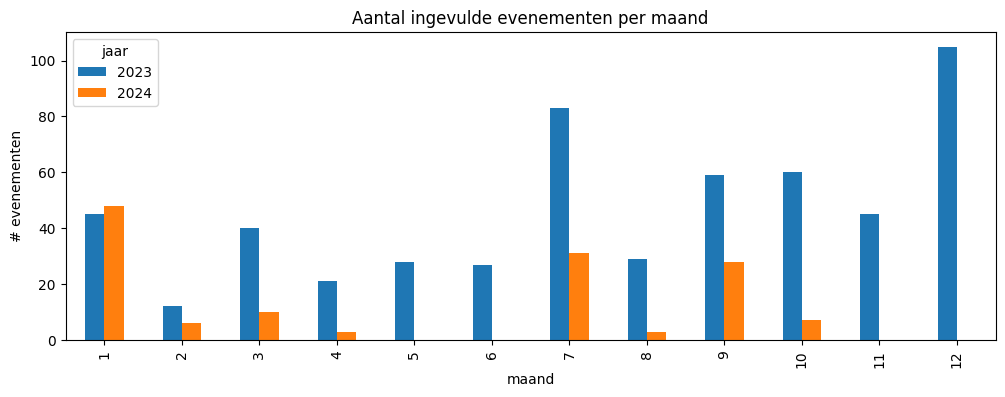

Totaal ingevulde evenementen per jaar:
Datum
2023    554
2024    136
Name: Titel, dtype: int64


In [19]:
# Controle: hoe volledig is de evenementenkalender? (aantal ingevulde evenementdagen per maand)
ruw = pd.read_excel("Evenementen_Leuven.xlsx")
ruw.columns = ruw.columns.str.strip()
ruw = ruw[(ruw['Datum'] >= '2023-01-01') & (ruw['Datum'] <= '2024-12-31')]
dekking = (ruw.assign(jaar=ruw['Datum'].dt.year, maand=ruw['Datum'].dt.month, ingevuld=ruw['Titel'].notna())
              .pivot_table(index='maand', columns='jaar', values='ingevuld', aggfunc='sum'))
dekking.plot(kind='bar', figsize=(12, 4), title='Aantal ingevulde evenementen per maand')
plt.ylabel('# evenementen')
plt.show()
print("Totaal ingevulde evenementen per jaar:")
print(ruw.groupby(ruw['Datum'].dt.year)['Titel'].count())

> **Let op - datakwaliteit:** de evenementenkalender is voor **2024 veel minder volledig** ingevuld dan voor 2023. In 2024 staan veel datums zonder titel en in **november - december 2024 staat er niets** (geen kerstmarkt, wintertuin, Dieric Bouts festival, ... terwijl die er in 2023 wel staan). Ook de wekelijkse markt staat enkel in 2023. Prophet gaat er van uit dat een evenement dat niet in de lijst staat, ook niet heeft plaatsgevonden. Dit heeft gevolgen voor de interpretatie van de resultaten (zie conclusie).

## 3.2: Prophet model

In [20]:
## Prophet model met evenementen

# holidays dataframe in het formaat dat Prophet verwacht (ds = datum, holiday = naam van het evenement)
holidays = evenementen_leuven.rename(columns={'Datum': 'ds', 'activiteit': 'holiday'})[['holiday', 'ds']]

# prophet model met evenementen (zelfde instellingen als model 2, zodat we eerlijk kunnen vergelijken)
m_ev = Prophet(holidays=holidays, yearly_seasonality=True, seasonality_mode='additive', mcmc_samples=500)

# fit het model op de historische data
m_ev.fit(daily_total_visits[['ds', 'y']])

# 14 dagen in de toekomst voorspellen
forecast_days = 14
future_ev = m_ev.make_future_dataframe(periods=forecast_days)

# maak de voorspelling
forecast_ev = m_ev.predict(future_ev)

# negatieve voorspellingen naar 0 (een negatief aantal bezoekers bestaat niet)
forecast_ev.loc[forecast_ev['yhat'] < 0, 'yhat'] = 0

# laatste dagen van de voorspelling (= de 14 toekomstige dagen)
forecast_ev[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail()

11:53:25 - cmdstanpy - INFO - CmdStan start processing
chain 1:   0%|          | 0/500 [00:00<?, ?it/s, (Warmup)]





chain 1:  20%|██        | 100/500 [00:02<00:11, 34.13it/s, (Warmup)]


chain 1:  40%|████      | 200/500 [00:06<00:09, 30.89it/s, (Warmup)]



chain 1:  50%|█████     | 251/500 [00:08<00:08, 30.44it/s, (Sampling)]



chain 1:  70%|███████   | 350/500 [00:12<00:05, 25.25it/s, (Sampling)]


chain 1:  90%|█████████ | 450/500 [00:19<00:02, 20.24it/s, (Sampling)]


chain 2: 100%|██████████| 500/500 [00:23<00:00, 21.49it/s, (Sampling completed)]

chain 3: 100%|██████████| 500/500 [00:23<00:00, 21.48it/s, (Sampling completed)]


chain 4: 100%|██████████| 500/500 [00:23<00:00, 21.48it/s, (Sampling completed)]


11:53:48 - cmdstanpy - INFO - CmdStan done processing.
11:53:48 - cmdstanpy - WARNING - Non-fatal error during sampling:
Exception: normal_id_glm_lpdf: Matrix of independent variables is inf, but must be finite! (in 'prophet.stan', line 137, column 2 to line 142, column 4)
	Exception: normal_id_glm_lpdf: Matrix of independent variables is inf, but must be finite! (in 'prophet.stan', line 137, column 2 to line 142, column 4)
	Exception: normal_id_glm_lpdf: Scale vector is 0, but must be positive finite! (in 'prophet.stan', line 137, column 2 to line 142, column 4)
Exception: normal_id_glm_lpdf: Scale vector is 0, but must be positive finite! (in 'prophet.stan', line 137, column 2 to line 142, column 4)
Exception: normal_id_glm_lpdf: Matrix of independent variables is inf, but must be finite! (in 'prophet.stan', line 137, column 2 to line 142, column 4)
	Exception: normal_id_glm_lpdf: Matrix of independent variables is inf, but must be finite! (in 'prophet.stan', line 137, column 2 to l

,ds,yhat,yhat_lower,yhat_upper
740,2025-01-10,109212.336290,90265.517730,129717.818330
741,2025-01-11,101831.860287,83149.181491,119389.351124
742,2025-01-12,57806.248177,40274.633596,77045.041638
743,2025-01-13,80256.538355,61273.331484,98275.151341
744,2025-01-14,89472.985814,71271.595254,106638.827263


## 3.3: Visualisatie Prophet model met evenementen

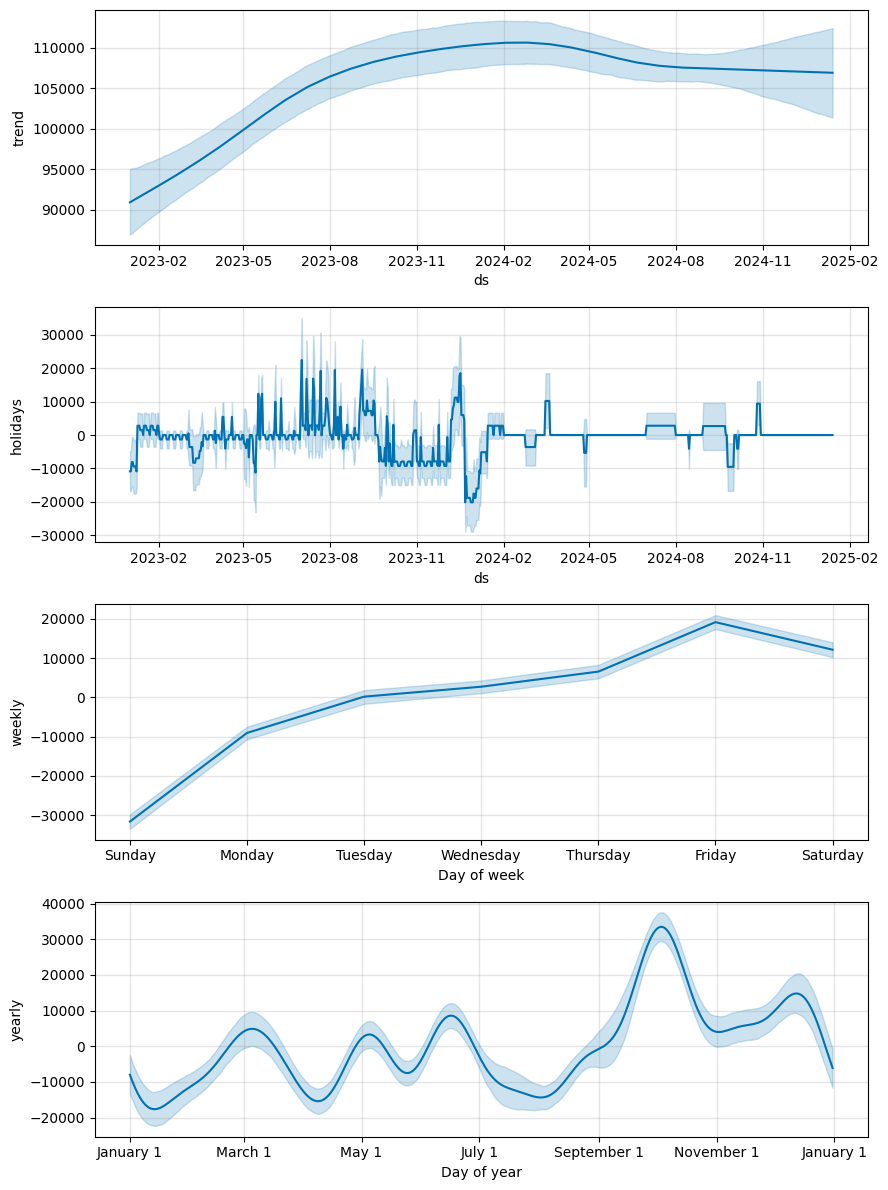

In [21]:
# Componenten van het model: trend, evenementen (holidays), wekelijkse en jaarlijkse seizoenaliteit
fig_ev = m_ev.plot_components(forecast_ev)
plt.show()

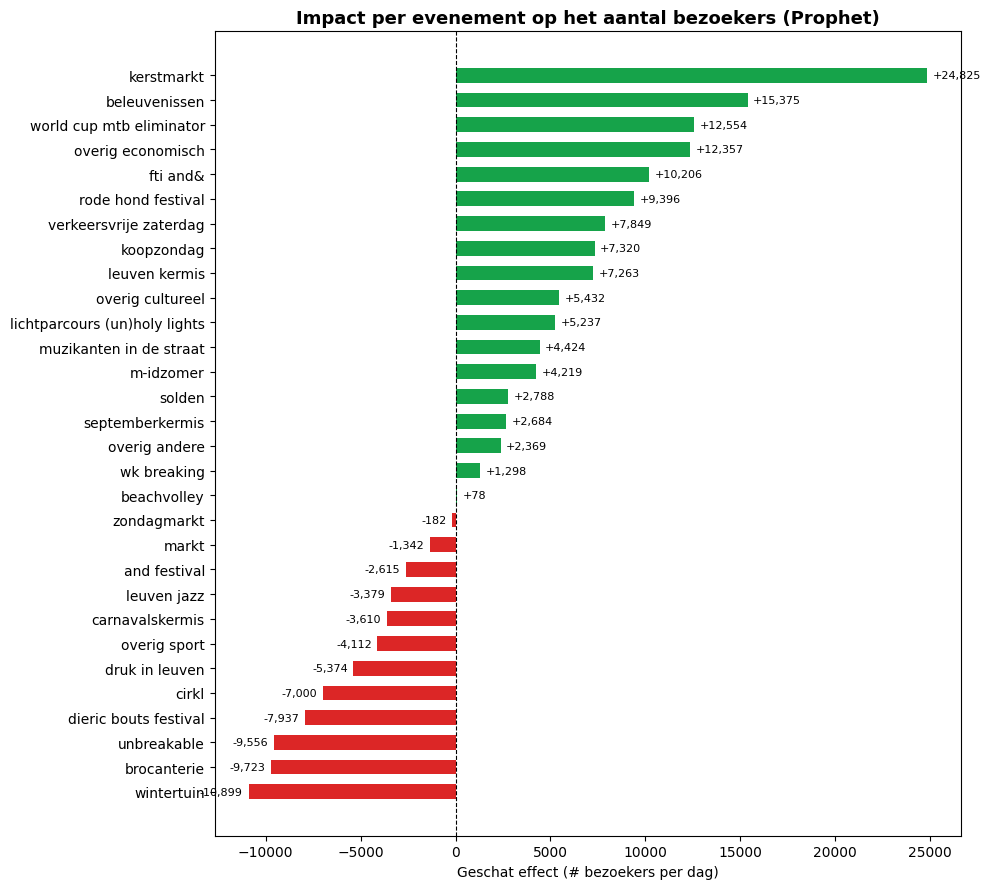

In [22]:
# Impact per evenement: het geschatte effect (in # bezoekers) dat Prophet aan elk evenement toekent
impacts_ev = []
for h in m_ev.train_holiday_names:
    if h in forecast_ev.columns:
        val = forecast_ev.loc[forecast_ev[h].abs() > 1e-3, h]
        impacts_ev.append({'Evenement': h, 'Impact (#)': val.iloc[0] if len(val) > 0 else 0.0})

df_event_impact = pd.DataFrame(impacts_ev).sort_values(by='Impact (#)')

plt.figure(figsize=(10, 9))
colors = ['#dc2626' if x < 0 else '#16a34a' for x in df_event_impact['Impact (#)']]
bars = plt.barh(df_event_impact['Evenement'], df_event_impact['Impact (#)'], color=colors, height=0.6)
plt.axvline(0, color='black', linewidth=0.8, linestyle='--')
plt.title('Impact per evenement op het aantal bezoekers (Prophet)', fontsize=13, fontweight='bold')
plt.xlabel('Geschat effect (# bezoekers per dag)')
for bar in bars:
    w = bar.get_width()
    plt.text(w + (300 if w >= 0 else -300), bar.get_y() + bar.get_height()/2, f"{w:+,.0f}",
             va='center', ha='left' if w >= 0 else 'right', fontsize=8)
plt.tight_layout()
plt.show()

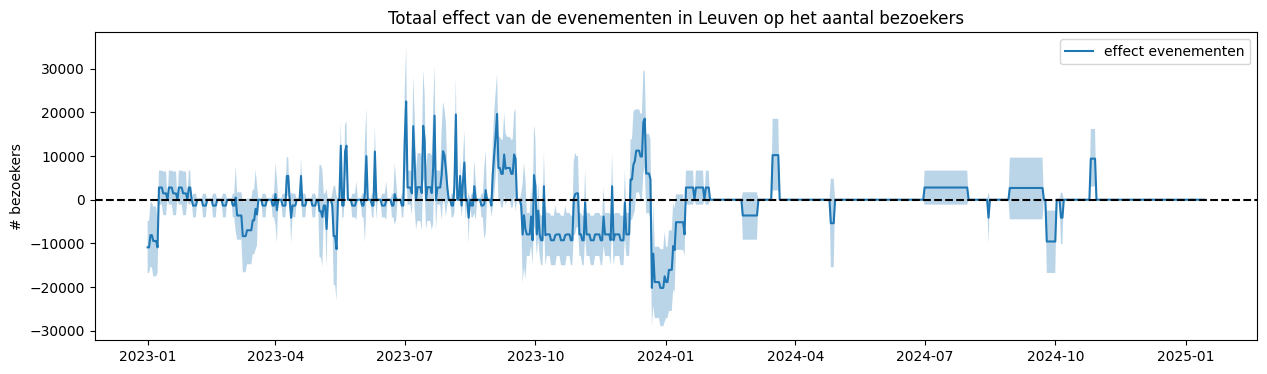

In [23]:
# Totale effect van alle evenementen samen over de tijd (met onzekerheidsinterval)
plt.figure(figsize=(15, 4))
plt.plot(forecast_ev['ds'], forecast_ev['holidays'], label='effect evenementen')
plt.fill_between(forecast_ev['ds'], forecast_ev['holidays_lower'], forecast_ev['holidays_upper'], alpha=0.3)
plt.axhline(0, color='black', linestyle='--')
plt.title('Totaal effect van de evenementen in Leuven op het aantal bezoekers')
plt.ylabel('# bezoekers')
plt.legend()
plt.show()

## 3.4: Error

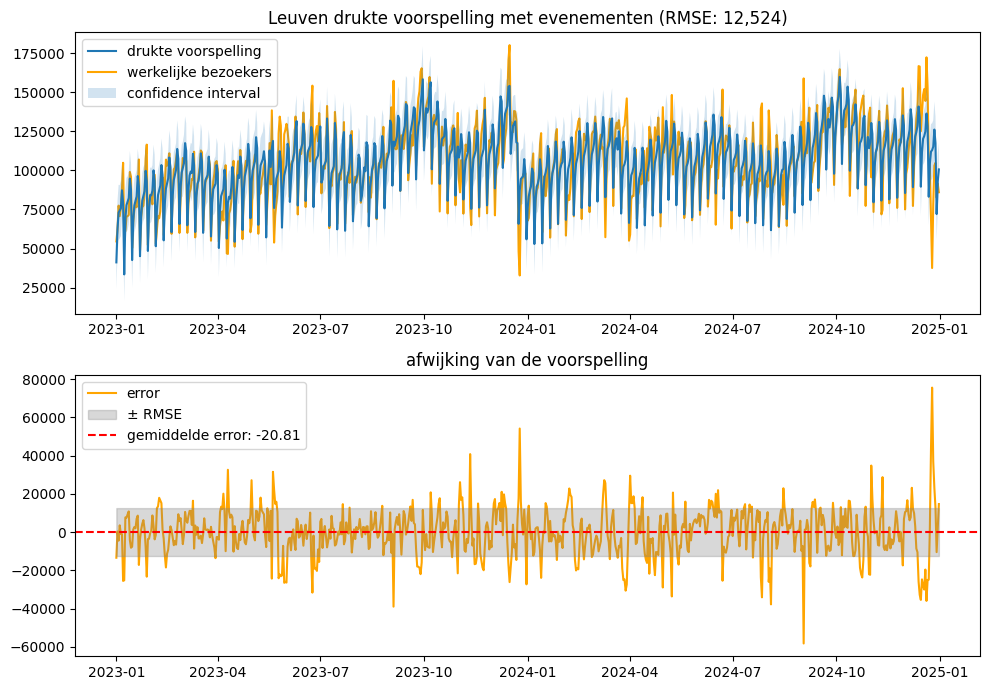

In [24]:
# Voorspelling koppelen aan de werkelijke data
forecast_ev_new = forecast_ev[forecast_ev['ds'] > daily_total_visits['ds'].max()]
ProphetFit_ev = forecast_ev.merge(daily_total_visits[['ds', 'y']], on='ds')

# error: positief = overschatting, negatief = onderschatting
ProphetFit_ev['error'] = ProphetFit_ev['yhat'] - ProphetFit_ev['y']
RMSE_ev = np.sqrt((ProphetFit_ev['error'] ** 2).mean())

plt.figure(figsize=(10, 7))

# --- Plot 1: voorspelling vs werkelijkheid ---
plt.subplot(2, 1, 1)
plt.plot(ProphetFit_ev['ds'], ProphetFit_ev['yhat'], label='drukte voorspelling', zorder=1)
plt.plot(ProphetFit_ev['ds'], ProphetFit_ev['y'], label='werkelijke bezoekers', zorder=0, color='orange')
plt.fill_between(ProphetFit_ev['ds'], ProphetFit_ev['yhat_upper'], ProphetFit_ev['yhat_lower'], alpha=0.2, label='confidence interval')
plt.title(f'Leuven drukte voorspelling met evenementen (RMSE: {RMSE_ev:,.0f})')
plt.legend()

# --- Plot 2: error ---
plt.subplot(2, 1, 2)
plt.plot(ProphetFit_ev['ds'], ProphetFit_ev['error'], label='error', color='orange', zorder=0)
plt.fill_between(ProphetFit_ev['ds'], RMSE_ev, -RMSE_ev, alpha=0.3, color='gray', label='± RMSE')
avg_error = ProphetFit_ev['error'].mean()
plt.axhline(avg_error, color='red', linestyle='--', label=f'gemiddelde error: {avg_error:.2f}')
plt.title('afwijking van de voorspelling')
plt.legend()
plt.tight_layout()
plt.show()

In [25]:
# Vergelijking van de modellen op de trainingsdata (goodness of fit)
def metrics(fit):
    e = fit['yhat'] - fit['y']
    return {'RMSE': np.sqrt((e ** 2).mean()),
            'MAE': e.abs().mean(),
            'MAPE (%)': (e.abs() / fit['y']).mean() * 100}

vergelijking = pd.DataFrame({
    '1. Basis (geen extra info)': metrics(ProphetFit),
    '2. Academische kalender': metrics(ProphetFit2),
    '3. Evenementen': metrics(ProphetFit_ev),
}).T.round(1)
vergelijking

,RMSE,MAE,MAPE (%)
1. Basis (geen extra info),13207.1,9967.6,10.1
2. Academische kalender,12808.0,9568.2,9.7
3. Evenementen,12523.9,9337.9,9.5


## 3.5: Validatie op een testset

De metrics hierboven zijn berekend op de **trainingsdata**: het model heeft die dagen zelf gezien, dus ze zeggen vooral iets over hoe goed het model *past* (fit). Of het model echt kan **voorspellen**, testen we door de laatste 8 weken (november - december 2024) apart te houden: het model wordt gefit op de data tot en met 2024-11-05 en voorspelt daarna de 8 weken die het nooit gezien heeft.

We gebruiken hier geen MCMC (standaard `mcmc_samples=0`), enkel de puntschatting, zodat dit snel loopt.

In [26]:
# Train / test split in de tijd: GEEN random split (dat zou toekomstige info lekken naar de training)
test_dagen = 56
split_datum = daily_total_visits['ds'].max() - pd.Timedelta(days=test_dagen)
train = daily_total_visits.loc[daily_total_visits['ds'] <= split_datum, ['ds', 'y']]
test = daily_total_visits.loc[daily_total_visits['ds'] > split_datum, ['ds', 'y']]

holidays_academisch = pd.read_excel("Academische_kalender_2022_2025.xlsx").rename(columns={'Datum': 'ds', 'activiteit': 'holiday'})
holidays_academisch['holiday'] = holidays_academisch['holiday'].str.lower()
holidays_academisch = holidays_academisch.dropna(subset=['holiday'])

modellen = {
    '1. Basis (geen extra info)': Prophet(yearly_seasonality=True, seasonality_mode='multiplicative'),
    '2. Academische kalender': Prophet(holidays=holidays_academisch, yearly_seasonality=True, seasonality_mode='additive'),
    '3. Evenementen': Prophet(holidays=holidays, yearly_seasonality=True, seasonality_mode='additive'),
}

test_resultaten = {}
test_voorspellingen = {}
for naam, model in modellen.items():
    model.fit(train)
    pred = model.predict(test[['ds']])
    pred.loc[pred['yhat'] < 0, 'yhat'] = 0
    fit = pred[['ds', 'yhat']].merge(test, on='ds')
    test_resultaten[naam] = metrics(fit)
    test_voorspellingen[naam] = fit

print(f"Training: {train['ds'].min().date()} t.e.m. {train['ds'].max().date()} | Test: {test['ds'].min().date()} t.e.m. {test['ds'].max().date()}")
pd.DataFrame(test_resultaten).T.round(1)

Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
11:53:56 - cmdstanpy - INFO - Chain [1] start processing
11:53:57 - cmdstanpy - INFO - Chain [1] done processing
Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
11:53:57 - cmdstanpy - INFO - Chain [1] start processing
11:53:57 - cmdstanpy - INFO - Chain [1] done processing
Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent o

Training: 2023-01-01 t.e.m. 2024-11-05 | Test: 2024-11-06 t.e.m. 2024-12-31


,RMSE,MAE,MAPE (%)
1. Basis (geen extra info),20442.0,16115.7,16.2
2. Academische kalender,20439.0,16138.3,16.2
3. Evenementen,26333.5,17986.8,16.9


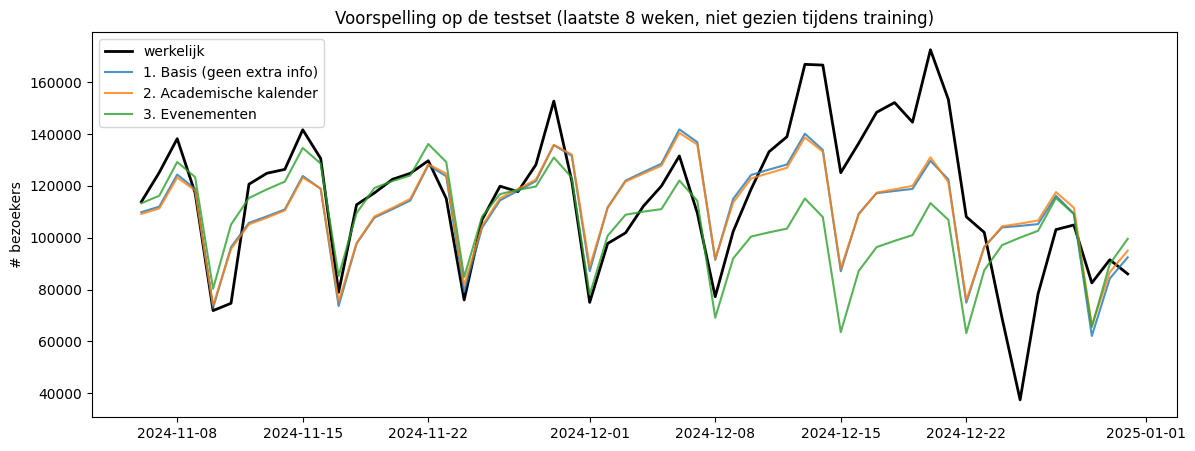

In [27]:
# Visueel: voorspelling op de testset vs werkelijkheid
plt.figure(figsize=(14, 5))
plt.plot(test['ds'], test['y'], color='black', linewidth=2, label='werkelijk')
for naam, fit in test_voorspellingen.items():
    plt.plot(fit['ds'], fit['yhat'], label=naam, alpha=0.8)
plt.title('Voorspelling op de testset (laatste 8 weken, niet gezien tijdens training)')
plt.ylabel('# bezoekers')
plt.legend()
plt.show()

#### **Conclusie**: Druktemodel met evenementen

**Componenten**
- `trend`: stijgt sterk in 2023 (± 91.000 → 110.000 bezoekers/dag) en vlakt af / daalt licht vanaf voorjaar 2024.
- `weekly`: zelfde patroon als bij de vorige modellen: zondag is veruit de rustigste dag (± -32.000 t.o.v. gemiddeld), vrijdag de drukste (± +19.000), gevolgd door zaterdag.
- `yearly`: grote piek eind september - oktober (start academiejaar), tweede piek in december (eindejaarsshopping), dalen in januari (examens), de paasvakantie en de zomer (juli - augustus).
- `holidays` (evenementen): het effect is in 2023 veel "drukker" dan in 2024, omdat er in 2024 veel minder evenementen in de kalender staan (zie datakwaliteit hierboven).

**Impact per evenement**
- Grootste positieve effecten: **kerstmarkt** (± +25.000 bezoekers/dag), **Beleuvenissen** (± +15.500), World Cup MTB eliminator, koopzondag, Leuven kermis, Rode Hond festival.
- Sommige effecten zijn **niet logisch**: wintertuin (± -11.000), Dieric Bouts festival (-8.300), brocanterie, ... krijgen een negatief effect. Dat komt niet doordat deze evenementen mensen wegjagen, maar doordat ze **samenvallen met rustige periodes**: de wintertuin loopt tot eind december / tussen kerst en nieuwjaar en het Dieric Bouts festival loopt maanden (o.a. in de kerstvakantie). Prophet kan het effect van het evenement dan niet goed scheiden van het effect van de periode -> het model "verdeelt" de daling over evenement en seizoen.
- `markt` (elke do/vr/za) heeft nauwelijks effect (-1.400): de markt valt altijd op dezelfde weekdagen en zit dus al in de **wekelijkse seizoenaliteit**.

**Fout / goodness of fit (trainingsdata)**

| Model | RMSE | MAE | MAPE |
|---|---|---|---|
| 1. Basis | 13.207 | 9.968 | 10,1 % |
| 2. Academische kalender | 12.813 | 9.571 | 9,7 % |
| 3. Evenementen | **12.526** | **9.340** | **9,5 %** |

Op de trainingsdata past het model met evenementen het best: de RMSE daalt met ± 5 % t.o.v. het basismodel. De verbetering is wel beperkt: het grootste deel van de variatie wordt al verklaard door de trend en de week- en jaarseizoenaliteit. De gemiddelde fout ligt rond 0, dus het model over- of onderschat niet systematisch.

**Testset (laatste 8 weken, niet gezien tijdens training)**

| Model | RMSE | MAE | MAPE |
|---|---|---|---|
| 1. Basis | 20.442 | 16.116 | 16,2 % |
| 2. Academische kalender | 20.439 | 16.138 | 16,2 % |
| 3. Evenementen | 26.334 | 17.987 | 16,9 % |

Op nieuwe data is het model met evenementen juist **slechter**. Vooral in december 2024 onderschat het de drukte met 30.000 - 60.000 bezoekers per dag. De verklaring: in 2023 werd de decemberpiek toegeschreven aan kerstmarkt, wintertuin, lichtparcours, ... Die evenementen staan **niet** in de kalender voor 2024, dus het model voorspelt die extra drukte niet. Het basismodel heeft de decemberpiek wel in de jaarlijkse seizoenaliteit gestoken en doet het daarom beter.

**Algemene conclusie:** evenementen kunnen de voorspelling verbeteren, maar **alleen als de evenementenkalender volledig en consistent is**, zowel in de trainingsperiode als in de periode die je wil voorspellen. Een betere fit op de trainingsdata betekent niet automatisch betere voorspellingen (vgl. overfitting / datalekken). Daarom moet je altijd valideren op een testset aan het einde van de tijdreeks. Ook op de testset blijven alle modellen eind december fouten maken (bv. kerstdag 25/12: werkelijk ± 37.500, voorspeld ± 100.000), omdat er geen feestdagen zoals Kerstmis in de data zitten.

# 4. **Model met weer**

In [28]:
for file in os.listdir():
    print(file)

Academische_kalender_2022_2025.xlsx
Deel 2 - Oefening.ipynb
Evenementen_Leuven.xlsx
Leuven bestedingen 2023 - 2024.xlsx
Leuven bezoekers 2023 - 2024.xlsx
Leuven weerdata 2023 - 2024.csv


In [29]:
# Laad de weerdata
weer = pd.read_csv("Leuven weerdata 2023 - 2024.csv")

# converteer datetime naar datetime object
weer['datetime'] = pd.to_datetime(weer['datetime'], format = '%Y-%m-%d')

# dataframe weer
weer.head()

,name,datetime,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,dew,humidity,...,solarenergy,uvindex,severerisk,sunrise,sunset,moonphase,conditions,description,icon,stations
0,Leuven,2023-01-01,15.8,10.5,12.8,15.8,10.5,12.8,7.8,72.9,...,1.5,1,NaN,2023-01-01T08:43:55,2023-01-01T16:45:34,0.31,"Rain, Partially cloudy",Partly cloudy throughout the day with rain.,rain,"06465099999,06459099999,06439099999,0644709999..."
1,Leuven,2023-01-02,13.6,6.6,10.0,13.6,3.8,8.5,8.1,88.2,...,1.2,1,NaN,2023-01-02T08:43:49,2023-01-02T16:46:37,0.35,"Rain, Partially cloudy",Partly cloudy throughout the day with a chance...,rain,"06439099999,06447099999,C1923,06458099999,0645..."
2,Leuven,2023-01-03,8.8,3.9,6.8,5.3,0.9,3.6,5.0,88.5,...,1.6,1,NaN,2023-01-03T08:43:40,2023-01-03T16:47:43,0.38,"Rain, Partially cloudy",Partly cloudy throughout the day with rain.,rain,"06439099999,F4778,06447099999,C1923,0645809999..."
3,Leuven,2023-01-04,12.6,8.5,11.1,12.6,4.4,10.2,9.2,88.1,...,1.0,1,NaN,2023-01-04T08:43:28,2023-01-04T16:48:51,0.41,"Rain, Partially cloudy",Partly cloudy throughout the day with rain.,rain,"06439099999,F4778,06447099999,C1923,0645809999..."
4,Leuven,2023-01-05,11.3,10.0,10.7,11.3,7.5,10.6,8.6,86.9,...,1.5,1,NaN,2023-01-05T08:43:12,2023-01-05T16:50:01,0.45,"Rain, Partially cloudy",Partly cloudy throughout the day with late aft...,rain,"06459099999,06439099999,06447099999,C1923,0645..."


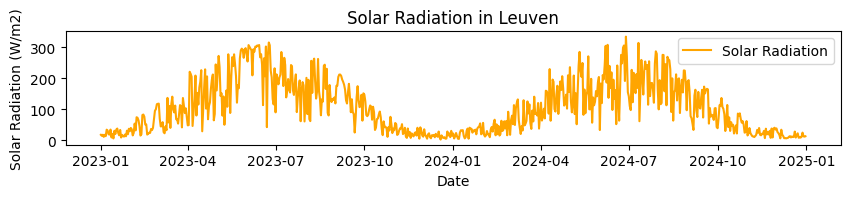

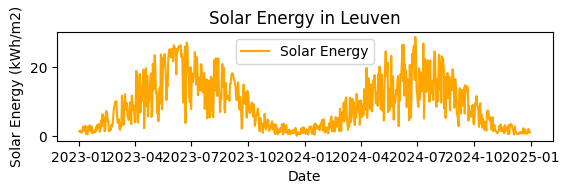

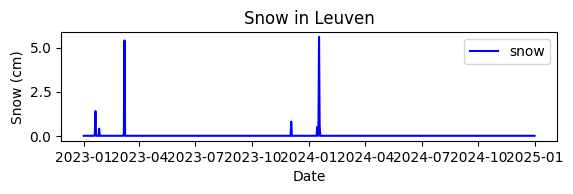

In [30]:
plt.figure(figsize = (10, 5))

# aantal plots instellen
plt.subplot(3, 1, 1)

# --- Plot 1 ---
plt.plot(weer['datetime'], weer['solarradiation'], color = 'orange', label = 'Solar Radiation')
plt.legend()
plt.title('Solar Radiation in Leuven')
plt.xlabel('Date')  
plt.ylabel('Solar Radiation (W/m2)')
plt.show()

# --- Plot 2 ---
plt.subplot(3, 1, 2)
plt.plot(weer['datetime'], weer['solarenergy'], color = 'orange', label = 'Solar Energy')
plt.legend()
plt.title('Solar Energy in Leuven')
plt.xlabel('Date')  
plt.ylabel('Solar Energy (kWh/m2)')
plt.show()

# --- Plot 3 ---
plt.subplot(3, 1, 3)
plt.plot(weer['datetime'], weer['snow'], color = 'blue', label = 'snow')
plt.legend()
plt.title('Snow in Leuven')
plt.xlabel('Date')
plt.ylabel('Snow (cm)')
plt.show()

In [31]:
# wat zijn de unieke weerscondities?
print(weer['conditions'].unique())

# print de eerste rij om de waarden te bekijken
print(weer.iloc[0, :])

<StringArray>
[      'Rain, Partially cloudy', 'Snow, Rain, Partially cloudy',
         'Snow, Rain, Overcast',                     'Overcast',
             'Partially cloudy',               'Rain, Overcast',
                        'Clear',                         'Rain',
                   'Snow, Rain',       'Snow, Partially cloudy']
Length: 10, dtype: str
name                                                           Leuven
datetime                                          2023-01-01 00:00:00
tempmax                                                          15.8
tempmin                                                          10.5
temp                                                             12.8
feelslikemax                                                     15.8
feelslikemin                                                     10.5
feelslike                                                        12.8
dew                                                               7.8
humidity

In [32]:
weer.loc[weer['precip'] > 10, 'precip'] = 10
weer.loc[weer['snow'].isna(), 'snow'] = 0
weer.loc[weer['snow'] >10, 'snow'] = 1

# merge de weerdata met de bezoekersdata
daily_total_visits_weather = daily_total_visits.merge(weer[['datetime', 'precip', 'temp', 'windspeed', 'snow']], left_on = 'ds', right_on = 'datetime')

del daily_total_visits_weather['datetime']

daily_total_visits_weather

,ds,y,7_day_avg,precip,temp,windspeed,snow
0,2023-01-01,54534,NaN,1.570,12.8,37.4,0.0
1,2023-01-02,61980,NaN,3.296,10.0,29.6,0.0
2,2023-01-03,77460,NaN,0.372,6.8,33.2,0.0
3,2023-01-04,70758,NaN,2.153,11.1,41.0,0.0
4,2023-01-05,76628,NaN,0.180,10.7,29.6,0.0
...,...,...,...,...,...,...,...
726,2024-12-27,103122,93020.571429,0.000,1.8,7.1,0.0
727,2024-12-28,104896,86108.571429,0.000,0.3,12.8,0.0
728,2024-12-29,82572,82467.714286,0.009,1.0,16.3,0.0
729,2024-12-30,91496,80959.857143,0.057,3.5,19.9,0.0


In [33]:
# Prophet model met weerdata
m3 = Prophet(
    holidays=holidays[['holiday', 'ds']],
    yearly_seasonality=True,
    seasonality_mode='additive',
    mcmc_samples=500)

# add regressors
m3.add_regressor('precip')
m3.add_regressor('temp')    
m3.add_regressor('windspeed')
m3.add_regressor('snow')

# fit het model op de historische data
m3.fit(daily_total_visits_weather)

# zet de voorspelling
forecast_days = 14

# maak een dataframe dat de historische en de toekomstige data bevat
future3 = m3.make_future_dataframe(periods = forecast_days)

# merge de weerdata met de toekomstige data
future3 = future3.merge(weer[['datetime', 'precip', 'temp', 'windspeed', 'snow']], left_on = 'ds', right_on = 'datetime')
del future3['datetime']

# maak de voorspelling
forecast3 = m3.predict(future3)

# geef de voorspelling weer
forecast3[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail()

# zet de negatieve waarden in de voorspelling naar 0
forecast3.loc[forecast3['yhat'] < 0, 'yhat'] = 0

11:53:58 - cmdstanpy - INFO - CmdStan start processing
chain 1:   0%|          | 0/500 [00:00<?, ?it/s, (Warmup)]


chain 1:  20%|██        | 100/500 [00:02<00:10, 36.94it/s, (Warmup)]




chain 1:  50%|█████     | 251/500 [00:07<00:07, 31.23it/s, (Sampling)]





chain 1:  70%|███████   | 350/500 [00:11<00:05, 29.96it/s, (Sampling)]




chain 1:  90%|█████████ | 450/500 [00:14<00:01, 29.46it/s, (Sampling)]


chain 2: 100%|██████████| 500/500 [00:17<00:00, 29.14it/s, (Sampling completed)]

chain 3: 100%|██████████| 500/500 [00:17<00:00, 29.14it/s, (Sampling completed)]


chain 4: 100%|██████████| 500/500 [00:17<00:00, 29.14it/s, (Sampling completed)]


11:54:15 - cmdstanpy - INFO - CmdStan done processing.
11:54:15 - cmdstanpy - WARNING - Non-fatal error during sampling:
Exception: normal_id_glm_lpdf: Matrix of independent variables is inf, but must be finite! (in 'prophet.stan', line 137, column 2 to line 142, column 4)
	Exception: normal_id_glm_lpdf: Matrix of independent variables is inf, but must be finite! (in 'prophet.stan', line 137, column 2 to line 142, column 4)
	Exception: normal_id_glm_lpdf: Scale vector is 0, but must be positive finite! (in 'prophet.stan', line 137, column 2 to line 142, column 4)
Exception: normal_id_glm_lpdf: Matrix of independent variables is inf, but must be finite! (in 'prophet.stan', line 137, column 2 to line 142, column 4)
	Exception: normal_id_glm_lpdf: Scale vector is 0, but must be positive finite! (in 'prophet.stan', line 137, column 2 to line 142, column 4)
Exception: normal_id_glm_lpdf: Matrix of independent variables is inf, but must be finite! (in 'prophet.stan', line 137, column 2 to l

In [34]:
# verdeel het model in voorspelling en historische data
forecast3_old = forecast3[forecast3['ds'] <= daily_total_visits_weather['ds'].max()]
forecast3_new = forecast3[forecast3['ds'] > daily_total_visits_weather['ds'].max()]

# merge de voorspelling met de originele data
ProphetFit3 = forecast3.merge(daily_total_visits_weather, on = 'ds')

# bereken de error
ProphetFit3['error'] = ProphetFit3['yhat'] - ProphetFit3['y']

# bereken RMSE
RMSE = round(np.sqrt((ProphetFit3['error'] * ProphetFit3['error']).mean()), 2)

print(f"RMSE: {RMSE}")


RMSE: 12259.83


### RMSE interpretatie

De **RMSE** voor de voorspellingswaarde is **± 12.261 bezoekers**. Deze waarde geeft de gemiddelde grootte van de afwijking tussen de voorspelde en de echte waarden weer. Bij gemiddeld ± 105.000 bezoekers per dag is dat een afwijking van ongeveer **12 %**.

Omdat de fouten in de RMSE eerst gekwadrateerd worden, wegen grote fouten (uitschieters zoals kerstdag of oudejaarsavond) zwaarder door dan kleine. De RMSE is daarom altijd groter dan of gelijk aan de MAE.

Vergelijking (trainingsdata): basismodel 13.207, academische kalender 12.813, evenementen 12.526, **evenementen + weer 12.261**. Het weer zorgt dus voor een extra (kleine) verbetering van ± 2 % t.o.v. het model met enkel evenementen.

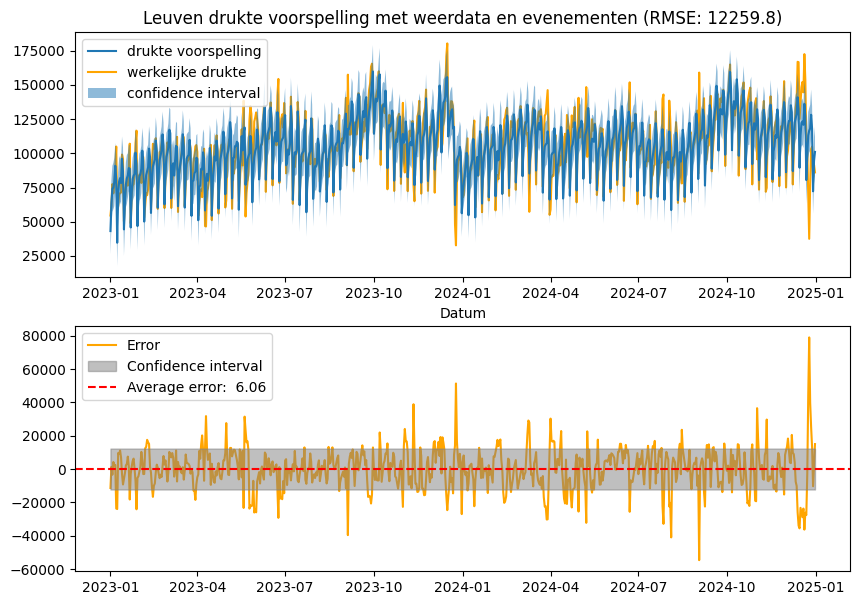

In [35]:
# Figuurgrootte instellen
plt.figure(figsize = (10, 7))

# --- Plot 1 ---
plt.subplot(2, 1, 1)

# plot de voorspelde drukte
plt.plot(ProphetFit3['ds'], ProphetFit3['yhat'], label = 'drukte voorspelling', zorder = 1)

# plot de actuele drukte
plt.plot(ProphetFit3['ds'], ProphetFit3['y'], label = 'werkelijke drukte', zorder = 0, color = 'orange')

# voeg de onzekerheid intervallen toe
plt.fill_between(ProphetFit3['ds'], ProphetFit3['yhat_upper'], ProphetFit3['yhat_lower'], alpha = 0.5, label = 'confidence interval')

# titel en labels
plt.title('Leuven drukte voorspelling met weerdata en evenementen (RMSE: ' + str(round(RMSE, 1)) + ')')
plt.xlabel('Datum')
plt.legend()

# --- Plot 2 ---
plt.subplot(2, 1, 2)

plt.plot(ProphetFit3['ds'], ProphetFit3['error'], label = 'Error', color = 'orange', zorder = 0)
plt.fill_between(ProphetFit3['ds'], RMSE, -RMSE, alpha = 0.5, label = 'Confidence interval', color = 'gray')
avg_error = ProphetFit3['error'].mean()
plt.axhline(avg_error, color = 'red', linestyle = '--', label = f'Average error: {avg_error: .2f}')
plt.legend()


>**Taak:** Interpreteer het model

**Prophet Forecast Analysis (Holidays + Rain)** - Vergelijking met de vorige fit (model met enkel evenementen)

**Verbeteringen:**
- De RMSE daalt van ± 12.526 (enkel evenementen) naar **± 12.261** (evenementen + weer). Het model met weer past dus het best van alle modellen op de trainingsdata.
- De weerparameters hebben een **logisch en significant effect** (het onzekerheidsinterval van de coëfficiënten bevat geen 0, zie de tabel `regressor_coefficients`):
  - **neerslag**: ± -840 bezoekers per mm regen -> bij een regendag van 10 mm (max. na capping) ± 8.400 bezoekers minder.
  - **temperatuur**: ± +390 bezoekers per °C -> een dag van 25 °C trekt ± 5.000 bezoekers meer dan een dag van 12 °C.
  - **wind**: ± -100 bezoekers per km/u.
  - **sneeuw**: ± -2.500 bezoekers op een sneeuwdag (wel zeer onzeker, er zijn maar enkele sneeuwdagen).
- Een deel van de dagelijkse schommelingen die eerst in de error zaten, wordt nu verklaard door het weer (bv. een regenachtige zaterdag).

**Gelijkaardigheden:**
- Trend, wekelijkse seizoenaliteit (zondag laag, vrijdag hoog) en jaarlijkse seizoenaliteit (piek start academiejaar en december, dal in januari en de zomer) blijven bijna identiek. Het weer is een **verfijning**, geen fundamentele verandering van het model.
- De effecten van de evenementen blijven in dezelfde richting (kerstmarkt sterk positief, wintertuin/Dieric Bouts negatief door overlap met de vakantieperiodes).
- De gemiddelde error ligt nog steeds rond 0 (± -36), dus geen systematische over- of onderschatting.

**Verschillen:**
- De verbetering is **klein** (± 2 %). Weer verklaart maar een klein deel van de drukte: de grootste drivers blijven het weekritme en het academiejaar. Een deel van het weereffect zat bovendien al in de jaarlijkse seizoenaliteit (zomer = warmer, maar ook vakantie).
- Dezelfde grote fouten blijven bestaan: rond kerst en nieuwjaar 2024 (bv. 25/12 overschatting van ± 80.000) en de onderschatte drukte in december 2024 (ontbrekende evenementen in de kalender).
- **Let op:** dit model voorspelt in de praktijk **geen** toekomstige dagen. Bij het mergen van `future3` met de weerdata vallen de 14 toekomstige dagen weg, omdat er voor 2025 geen weerdata is (inner merge). Om echt te voorspellen heb je dus een **weersvoorspelling** nodig voor de toekomstige dagen, en die is zelf ook onzeker. Dat is een nadeel van externe regressoren.

**Algemene Conclusie:**
Het model met evenementen + weer geeft de beste fit op de historische data (RMSE ± 12.261, ± 12 % van het gemiddelde aantal bezoekers). Het weer heeft een logisch effect: regen, wind en sneeuw verlagen de drukte en warmte verhoogt ze. Het effect is wel klein in vergelijking met het weekritme en het academiejaar. De grootste winst valt niet te halen uit extra variabelen, maar uit **betere data**: een volledige evenementenkalender voor 2024, feestdagen (Kerstmis, Nieuwjaar, ...) en eventueel de academische kalender combineren met de evenementen. Daarnaast zou dit model, net als in 3.5, op een testset gevalideerd moeten worden, en voor echte voorspellingen zijn weersvoorspellingen nodig.

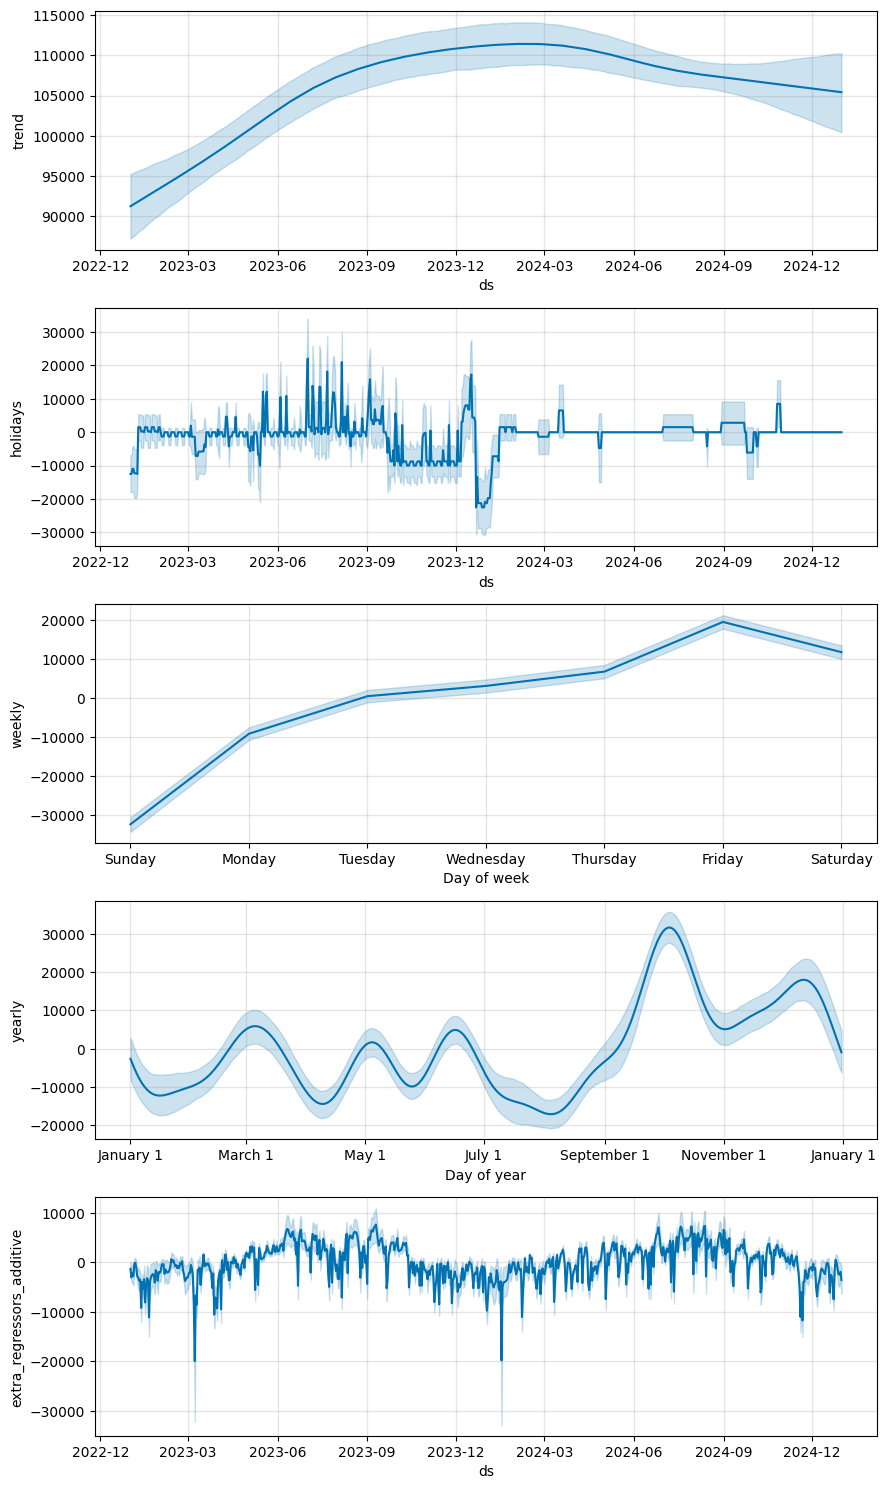

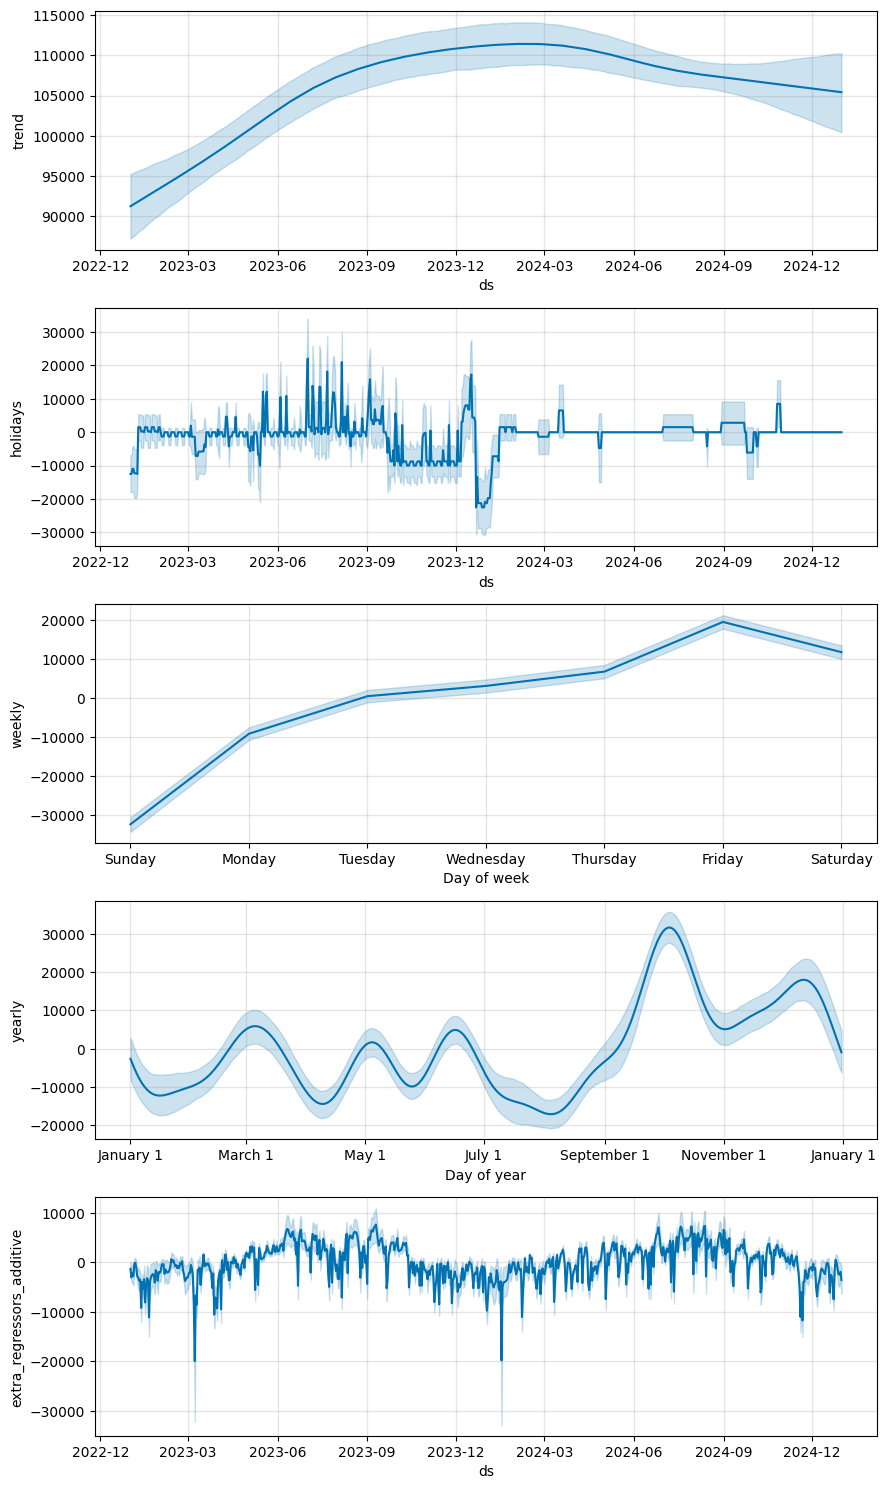

In [36]:
# Plot de individuele componenten van de voorspelling (e.g., trend, seizoensgebondenheid, feestdagen)
m3.plot_components(forecast3)   


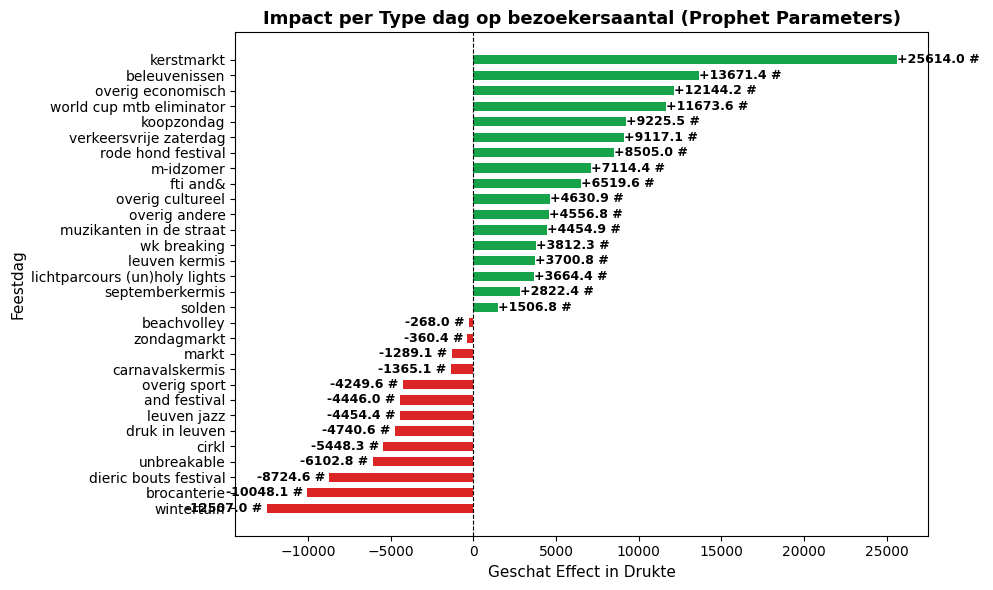

In [37]:
holiday_names = list(m3.train_holiday_names)

impacts = []
for h in holiday_names:
    if h in forecast3.columns:
        # Haal de niet-nul waarde op voor deze specifieke feestdag
        val = forecast3.loc[forecast3[h].abs() > 1e-3, h]
        impact = val.iloc[0] if len(val) > 0 else 0.0
        impacts.append({"Feestdag": h, "Impact (#)": impact})

df_holiday_impact = pd.DataFrame(impacts).sort_values(by="Impact (#)", ascending=True)

# Plot de impact per "feest"dag
plt.figure(figsize=(10, 6))
colors = ['#dc2626' if x < 0 else '#16a34a' for x in df_holiday_impact["Impact (#)"]]
bars = plt.barh(df_holiday_impact["Feestdag"], df_holiday_impact["Impact (#)"], color=colors, edgecolor='none', height=0.6)

plt.axvline(0, color='black', linewidth=0.8, linestyle='--')
plt.title("Impact per Type dag op bezoekersaantal (Prophet Parameters)", fontsize=13, fontweight='bold')
plt.xlabel("Geschat Effect in Drukte", fontsize=11)
plt.ylabel("Feestdag", fontsize=11)

# Toon getallen naast de staven
for bar in bars:
    width = bar.get_width()
    ha = 'left' if width >= 0 else 'right'
    offset = 1.0 if width >= 0 else -1.0
    plt.text(width + offset, bar.get_y() + bar.get_height()/2, f"{width:+.1f} # ",
             va='center', ha=ha, fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

In [38]:
# Effect van de weerparameters (regressoren) op het aantal bezoekers
# coef = verandering in # bezoekers per eenheid van de regressor (bv. per mm regen of per °C)
from prophet.utilities import regressor_coefficients
regressor_coefficients(m3).round(1)

,regressor,regressor_mode,center,coef_lower,coef,coef_upper
0,precip,additive,1.5,-1101.1,-832.7,-546.4
1,temp,additive,11.9,171.3,388.1,606.1
2,windspeed,additive,20.8,-187.5,-99.1,-6.5
3,snow,additive,0.0,-4774.3,-2522.6,-261.3


## 4.1: Validatie op de testset

Net zoals bij model 3 (zie 3.5) testen we ook het weermodel op de **laatste 8 weken** die het model niet gezien heeft. We gebruiken dezelfde `train` / `test` split, zodat de resultaten vergelijkbaar zijn.

Voor de testperiode gebruiken we de **werkelijk gemeten** weerdata. In de praktijk zou je een **weersvoorspelling** moeten gebruiken, die zelf ook onzeker is. De testscore hieronder is dus een iets te optimistische inschatting.

In [39]:
# Weermodel (evenementen + weer) fitten op de trainingsperiode
train_weer = train.merge(weer[['datetime', 'precip', 'temp', 'windspeed', 'snow']], left_on='ds', right_on='datetime').drop(columns='datetime')
test_weer = test.merge(weer[['datetime', 'precip', 'temp', 'windspeed', 'snow']], left_on='ds', right_on='datetime').drop(columns='datetime')

m_weer_test = Prophet(holidays=holidays[['holiday', 'ds']], yearly_seasonality=True, seasonality_mode='additive')
for regressor in ['precip', 'temp', 'windspeed', 'snow']:
    m_weer_test.add_regressor(regressor)
m_weer_test.fit(train_weer)

# voorspellen op de testperiode
pred_weer = m_weer_test.predict(test_weer.drop(columns='y'))
pred_weer.loc[pred_weer['yhat'] < 0, 'yhat'] = 0
fit_weer = pred_weer[['ds', 'yhat']].merge(test, on='ds')

test_resultaten['4. Evenementen + weer'] = metrics(fit_weer)
test_voorspellingen['4. Evenementen + weer'] = fit_weer

# overzicht van alle modellen op de testset
pd.DataFrame(test_resultaten).T.round(1)

Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
11:54:19 - cmdstanpy - INFO - Chain [1] start processing
11:54:19 - cmdstanpy - INFO - Chain [1] done processing


,RMSE,MAE,MAPE (%)
1. Basis (geen extra info),20442.0,16115.7,16.2
2. Academische kalender,20439.0,16138.3,16.2
3. Evenementen,26333.5,17986.8,16.9
4. Evenementen + weer,26951.1,18845.8,17.9


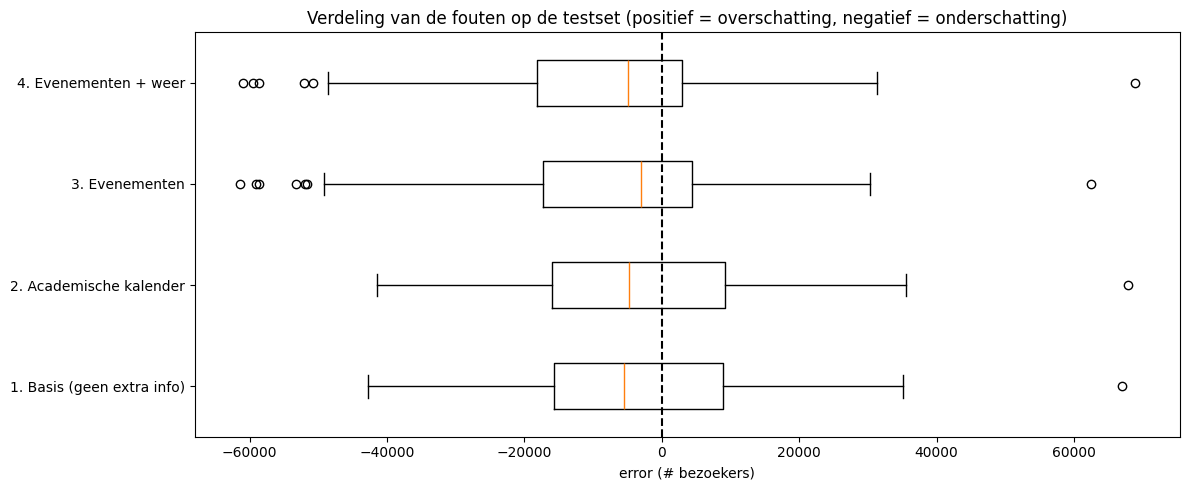

1. Basis (geen extra info)   -4100.0
2. Academische kalender      -3821.0
3. Evenementen               -9118.0
4. Evenementen + weer        -9566.0
dtype: float64

In [40]:
# Residuals (error) op de testset per model: verdeling van de fouten
fouten = pd.DataFrame({naam: (fit['yhat'] - fit['y']).values for naam, fit in test_voorspellingen.items()})

plt.figure(figsize=(12, 5))
plt.boxplot(fouten.values, tick_labels=fouten.columns, vert=False)
plt.axvline(0, color='black', linestyle='--')
plt.title('Verdeling van de fouten op de testset (positief = overschatting, negatief = onderschatting)')
plt.xlabel('error (# bezoekers)')
plt.tight_layout()
plt.show()

# gemiddelde fout (bias) per model op de testset
fouten.mean().round(0)

#### **Conclusie**: Validatie op de testset

| Model | RMSE trainingsdata | RMSE testset | MAPE testset |
|---|---|---|---|
| 1. Basis | 13.207 | **20.442** | **16,2 %** |
| 2. Academische kalender | 12.813 | **20.439** | **16,2 %** |
| 3. Evenementen | 12.524 | 26.334 | 16,9 % |
| 4. Evenementen + weer | ± 12.260 | 26.951 | 17,9 % |

- **Op de trainingsdata** wordt het model telkens beter naarmate we meer informatie toevoegen (model 4 heeft de laagste RMSE).
- **Op de testset** is het omgekeerd: de eenvoudige modellen (basis en academische kalender) voorspellen het best. De modellen met evenementen zijn ± 30 % slechter.
- Alle modellen maken op de testset grotere fouten dan op de trainingsdata (RMSE ± 20.000 - 27.000 i.p.v. ± 12.000 - 13.000). Dat is normaal: op data die het model niet gezien heeft, scoort een model altijd slechter.
- De oorzaak van het slechte resultaat van modellen 3 en 4 is de **onvolledige evenementenkalender** (zie 3.1): in november - december 2024 staan er geen evenementen in, terwijl het model in 2023 de decemberpiek aan de kerstmarkt en de wintertuin had toegeschreven. In de boxplot zie je dat modellen 3 en 4 in de testperiode vooral **onderschatten** (negatieve fouten).
- Het weer helpt op de testset niet: de weereffecten zijn klein (± -830 per mm regen, ± +390 per °C) in vergelijking met het probleem van de ontbrekende evenementen.

**Eindconclusie:** meer variabelen geven een betere fit, maar niet automatisch een betere voorspelling. Een extra variabele helpt enkel als ze **betrouwbaar en volledig** beschikbaar is, zowel in het verleden als voor de periode die je wil voorspellen. Voor deze data zouden we het **model met de academische kalender** kiezen. Eventueel kunnen we het weer toevoegen zodra de evenementenkalender voor 2024 aangevuld is.